# Artificial Neural Networks and Deep Learning

---

## Homework 1: Minimal Working Example

To make your first submission, follow these steps:
1. Create a folder named `[2024-2025] AN2DL/Homework 1` in your Google Drive.
2. Upload the `training_set.npz` file to this folder.
3. Upload the Jupyter notebook `Homework 1 - Minimal Working Example.ipynb`.
4. Load and process the data.
5. Implement and train your model.
6. Submit the generated `.zip` file to Codabench.


## 🌐 Connect Colab to Google Drive

In [1]:
from google.colab import drive

drive.mount('/gdrive')
%cd /gdrive/My Drive/[2024-2025] AN2DL/Homework 1

Mounted at /gdrive
/gdrive/My Drive/[2024-2025] AN2DL/Homework 1


## ⚙️ Import Libraries

In [2]:
# Set seed for reproducibility
seed = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['PYTHONHASHSEED'] = str(seed)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import cv2
import shutil
import logging
import random
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import requests
import seaborn as sns
import numpy as np
import pandas as pd
import tensorflow as tf
tfk = tf.keras
tfkl = tf.keras.layers
print(tf.__version__)

from tensorflow.keras.layers import Input, Dense, Dropout, Lambda
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet import preprocess_input
from tensorflow.keras import layers as tfkl
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from PIL import Image
from io import BytesIO

# Set seeds for random number generators in NumPy and Python
np.random.seed(seed)
random.seed(seed)

# Set seed for TensorFlow
tf.random.set_seed(seed)
tf.compat.v1.set_random_seed(seed)

# Reduce TensorFlow verbosity
tf.autograph.set_verbosity(0)
tf.get_logger().setLevel(logging.ERROR)
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)


2.17.1


## ⏳ Load the Data

In [3]:
# Load the training data
data_set = np.load('training_set.npz')
X = data_set['images']
y = data_set['labels']

# Getting current working directory
BASE_PATH = os.getcwd()

# Paths
DATASET_DIR =  os.path.join(BASE_PATH, 'dataset')

LEAF_DIR = os.path.join(BASE_PATH, 'leaf_dataset_splitted')
TRAINING_DIR = os.path.join(LEAF_DIR, 'training')
VALIDATION_DIR = os.path.join(LEAF_DIR, 'validation')

AUG_DIR =  os.path.join(BASE_PATH, 'aug')
RANDAUG_DIR = os.path.join(AUG_DIR, 'randaug')
MIXAUG_DIR = os.path.join(AUG_DIR, 'mixaug')

### 📑 Hyperparameters setting

In [4]:
# Define the labels
labels = ['Basophil',                       # 0
          'Eosinophil',                        # 1
          'Erythroblast',                     # 2
          'Immature granulocytes',     # 3
          'Lymphocyte',                     # 4
          'Monocyte',                        # 5
          'Neutrophil',                       # 6
          'Platelet']                           # 7



In [5]:
# Model hyperparameters
INPUT_SHAPE = (96, 96, 3)
IMAGE_SIZE = (INPUT_SHAPE[0], INPUT_SHAPE[1])
EPOCHS = 100
BATCH_SIZE = 32
DROPOUT_RATE = 0.4
LEARNING_RATE = 1e-4
LAMBDA = 1e-3
NUM_CLASSES = len(labels)
MODEL_NAME = "cnn"

### ❌ Remove unwanted images

In [6]:
!pip install imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 54.1 MB/s eta 0:00:00


In [7]:
import imagehash

# Define a function to generate a list of hash values for a given list of images
def generate_hash_list(images):
    hash_list = []
    for img in images:
        img_pil = Image.fromarray((img * 255).astype(np.uint8))
        img_hash = str(imagehash.phash(img_pil))
        hash_list.append(img_hash)
    return hash_list

# Generate a list of hash values for the images
hash_list = generate_hash_list(X)


In [8]:
# Remove unwanted images based on their hash values

unwanted_hashes = {"9fe878d070cad744", "c417f7079d623760"}

indices_to_remove = [idx for idx, img_hash in enumerate(hash_list) if img_hash in unwanted_hashes]

X_filtered = np.delete(X, indices_to_remove, axis=0)
y_filtered = np.delete(y, indices_to_remove, axis=0)

print(f"Removed {len(indices_to_remove)} images from the dataset.")


Removed 1800 images from the dataset.


In [9]:
X=X_filtered
y=y_filtered

### ⚖️ Define weights

In [10]:
# Define weights for class imbalance
total_samples = len(y)

# Ensure y is a one-dimensional array
y = np.squeeze(y)

print("Total Samples:", total_samples)
print("Number of Classes:", NUM_CLASSES)

# Count the number of samples for each class
class_counts = np.bincount(y)
print("Class Counts:", class_counts)

# Calculate the class weights
class_weights = total_samples / (NUM_CLASSES * class_counts)
for i, weight in enumerate(class_weights):
    print(f"Class {i} Weight: {weight:.2f}")


Total Samples: 11959
Number of Classes: 8
Class Counts: [ 852 2181 1085 2026  849  993 2330 1643]
Class 0 Weight: 1.75
Class 1 Weight: 0.69
Class 2 Weight: 1.38
Class 3 Weight: 0.74
Class 4 Weight: 1.76
Class 5 Weight: 1.51
Class 6 Weight: 0.64
Class 7 Weight: 0.91


### Checking numbers

In [11]:
def count_samples_classes(dir_path):
    # Define the labels
    labels = ['Basophil',                       # 0
          'Eosinophil',                        # 1
          'Erythroblast',                     # 2
          'Immature granulocytes',     # 3
          'Lymphocyte',                     # 4
          'Monocyte',                        # 5
          'Neutrophil',                       # 6
          'Platelet']                           # 7

    class_counts = {}

    for i in range(NUM_CLASSES):
        label_dir = os.path.join(dir_path, labels[i])
        if not os.path.exists(label_dir):
            print(f"Directory {label_dir} does not exist.")
            class_counts[labels[i]] = 0
            continue

        # Selecting all the images of the i-th class
        _, _, class_imgs = next(os.walk(label_dir), (None, None, []))
        count = len(class_imgs)

        # Storing the counter bound with the class target
        class_counts[labels[i]] = count

    return class_counts


### 🖼️ Load data

In [12]:
# Normalize data to the range [0, 1]
X = (X / 255).astype('float32')

# Convert labels to categorical format using one-hot encoding
y = tfk.utils.to_categorical(y)

In [13]:
# Transform X and y to a dataset
dataset = tf.data.Dataset.from_tensor_slices((X, y)).batch(1)

In [14]:
for images, labels in dataset.take(1):
    print("Training Data Shape:", images.shape)
    print("Training Label Shape:", labels.shape)


Training Data Shape: (1, 96, 96, 3)
Training Label Shape: (1, 8)


## 🔄 Process Data

### 🧩 Split Dataset

* Training set : 90%
* Validation set : 10%

In [15]:
# Split the data into training, validation, and testing sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=seed, stratify=y)



* Trainning set



In [16]:
# Transform to TensorFlow Dataset
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(1)

In [17]:
for images, labels in train_dataset.take(1):
    print("Training Data Shape:", images.shape)
    print("Training Label Shape:", labels.shape)

Training Data Shape: (1, 96, 96, 3)
Training Label Shape: (1, 8)


* Validation set

In [18]:
val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(1)

In [19]:
for images, labels in val_dataset.take(1):
    print("Validation Data Shape:", images.shape)
    print("Validation Label Shape:", labels.shape)

Validation Data Shape: (1, 96, 96, 3)
Validation Label Shape: (1, 8)


### White Noise

In [20]:
def add_white_noise(image, label, mean=0.0, stddev=0.1):
    noise = tf.random.normal(shape=tf.shape(image), mean=mean, stddev=stddev)
    image = tf.clip_by_value(image + noise, 0.0, 1.0)
    return image, label

### Data Augmentation

In [21]:
!pip install keras-cv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 650.7/650.7 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 950.8/950.8 kB 43.7 MB/s eta 0:00:00


In [22]:
import keras_cv

####   Mix-Augmentation

In [23]:
# Data augmentation using keras_cv
mix_aug = keras_cv.layers.AugMix(
    value_range=(0, 1),
    severity=0.2,
    num_chains=1,
    # chain_depth=[1, 3],
    alpha=2.0,
    seed=seed
)

In [24]:
# Augmentation function
def augment_data_mix(image, label):
    image = mix_aug(image)
    image = tf.squeeze(image, axis=0)
    label = tf.squeeze(label, axis=0)
    return image, label


In [25]:
# Apply augmentations
train_dataset_mixaug = train_dataset.map(
    augment_data_mix, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [26]:
for images, labels in train_dataset_mixaug.take(1):
    print("Training Data Shape:", images.shape)
    print("Training Label Shape:", labels.shape)

Training Data Shape: (32, 96, 96, 3)
Training Label Shape: (32, 8)


#### Mix-Up Augmentation

In [27]:
mix_up = keras_cv.layers.MixUp(alpha=0.2, seed=seed, input_shape=INPUT_SHAPE)

In [28]:
def augment_data_mixup(image, label):
    inputs = {"images": image, "labels": label}
    augmented = mix_up(inputs)
    image = augmented["images"]
    label = augmented["labels"]
    image = tf.squeeze(image, axis=0)
    label = tf.squeeze(label, axis=0)
    return image, label

In [29]:
# Apply augmentations
train_dataset_aug_mixup = train_dataset.map(
    augment_data_mix, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [30]:
for images, labels in train_dataset_aug_mixup.take(1):
    print("Training Data Shape:", images.shape)
    print("Training Label Shape:", labels.shape)

Training Data Shape: (32, 96, 96, 3)
Training Label Shape: (32, 8)


#### Dataset Augmentation

In [31]:
# Augmentation function
def augment_data(image, label):
    image, label = augment_data_mixup(image, label)
    image = mix_aug(image)

    return image, label

In [32]:
# Apply augmentations
train_dataset_aug = train_dataset.map(
    augment_data, num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [33]:
for images, labels in train_dataset_aug.take(1):
    print("Training Data Shape:", images.shape)
    print("Training Label Shape:", labels.shape)

Training Data Shape: (32, 96, 96, 3)
Training Label Shape: (32, 8)


In [34]:
train_dataset_aug_with_noise = train_dataset_aug.map(lambda image, label: add_white_noise(image, label),
                                         num_parallel_calls=tf.data.AUTOTUNE)

In [35]:
val_dataset_with_noise = val_dataset.map(lambda image, label: add_white_noise(image, label),
                                         num_parallel_calls=tf.data.AUTOTUNE)

## 🔎 Inspect Data

#### Display Random Images with Labels

In [ ]:
def display_random_augmented_images(dataset):
    # Take one batch from the dataset
    for images, labels in dataset.take(1):
        batch_size = images.shape[0]  # Display up to 'num_images' or the size of the batch

        # Set up subplot grid size
        cols = 4  # Display 4 images per row
        rows = (batch_size + cols - 1) // cols  # Calculate the number of rows
        plt.figure(figsize=(15, rows * 3))  # Adjust figure size

        # Iterate through the current batch of images and labels
        for i in range(batch_size):
            plt.subplot(rows, cols, i + 1)  # Create subplot
            # Convert the image to the range [0, 1] for display if needed
            image_to_display = images[i].numpy()
            plt.imshow(image_to_display)  # Display image
            plt.title(f"Label: {labels[i].numpy()}", fontsize=10)  # Set title
            plt.axis("off")  # Turn off axis

        plt.tight_layout()  # Adjust layout
        plt.show()


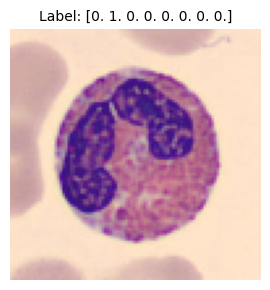

In [ ]:
display_random_augmented_images(train_dataset)

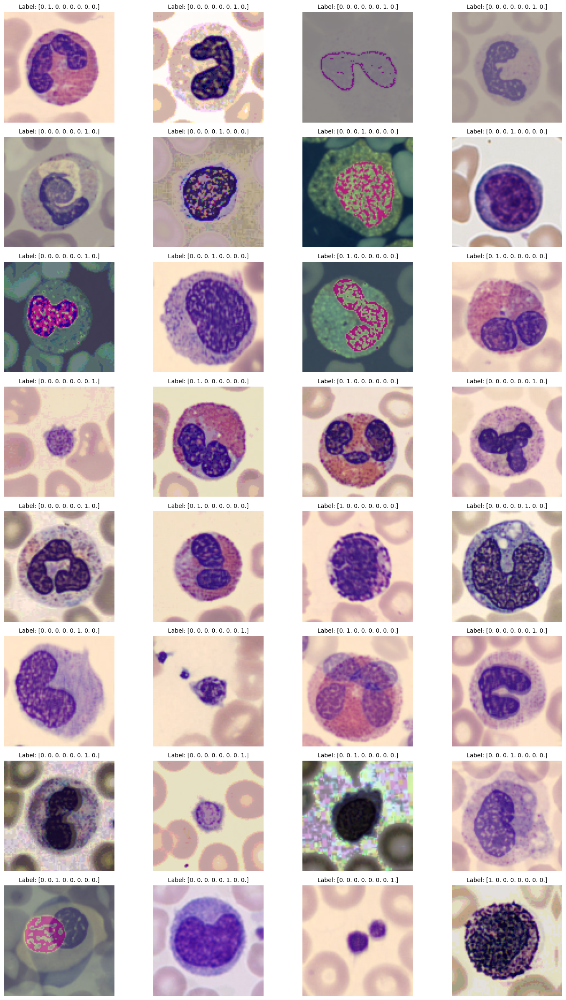

In [ ]:
display_random_augmented_images(train_dataset_mixaug)

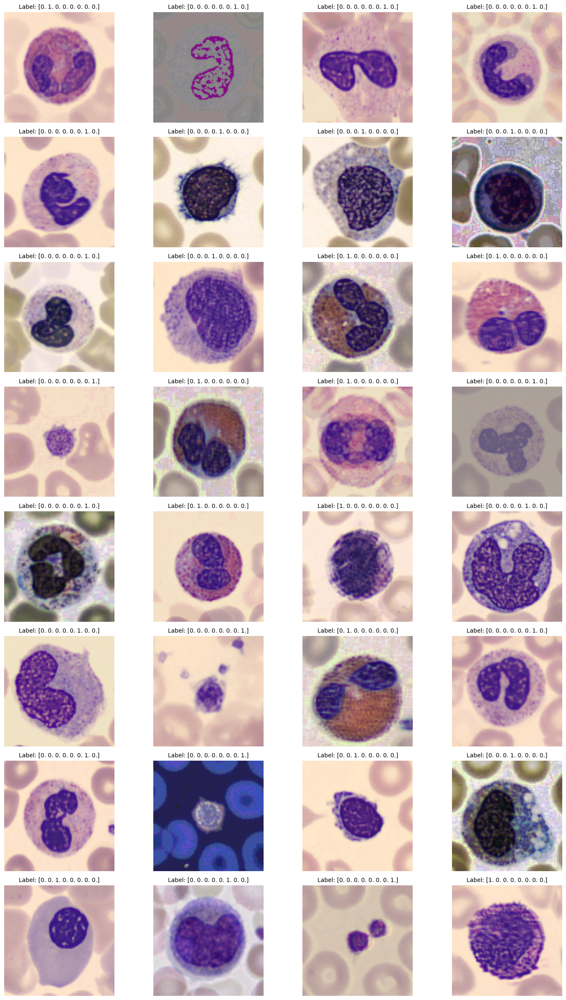

In [ ]:
display_random_augmented_images(train_dataset_aug)

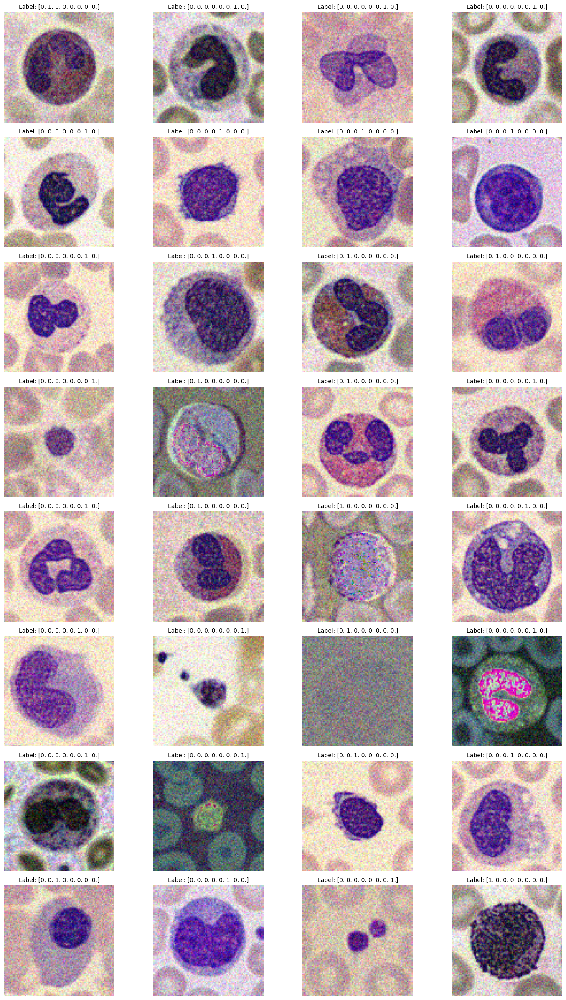

In [ ]:
display_random_augmented_images(train_dataset_aug_with_noise)

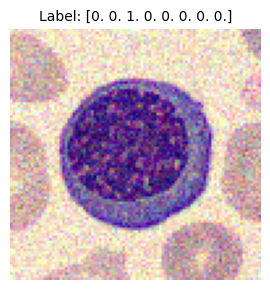

In [ ]:
display_random_augmented_images(val_dataset_with_noise)

## 🧮 Define Network Parameters

### Utilities

In [36]:
# Utility function to create folders and callbacks for training
def create_folders_and_callbacks(model_name):

  exps_dir = os.path.join('models')
  if not os.path.exists(exps_dir):
      os.makedirs(exps_dir)

  exp_dir = os.path.join(exps_dir, model_name)
  if not os.path.exists(exp_dir):
      os.makedirs(exp_dir)

  callbacks = []

  # Model checkpoint
  # ----------------
  ckpt_dir = os.path.join(exp_dir, 'ckpts')
  if not os.path.exists(ckpt_dir):
      os.makedirs(ckpt_dir)

  ckpt_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(ckpt_dir, 'cp.keras'),
    save_weights_only=False, # True to save only weights
    save_best_only=False) # True to save only the best epoch

  callbacks.append(ckpt_callback)

  # Early Stopping
  # --------------
  es_callback = tf.keras.callbacks.EarlyStopping(
      monitor='val_loss',
      patience=10,
      restore_best_weights=True)
  callbacks.append(es_callback)

  return callbacks

In [37]:
def save_model_weights(model, weight_name):
    model.save(weight_name)
    print(f"Model weights saved as {weight_name}")

In [38]:
# Helper function to get ground truth and predictions from dataset
def get_predictions_from_dataset(dataset, model):
    y_true = []
    y_pred = []

    for X_batch, y_batch in dataset:
        y_batch_pred = model.predict(X_batch, verbose=0)
        y_batch_pred_labels = np.argmax(y_batch_pred, axis=1)
        y_batch_true_labels = np.argmax(y_batch.numpy(), axis=1)

        y_true.extend(y_batch_true_labels)
        y_pred.extend(y_batch_pred_labels)

    return y_true, y_pred

In [39]:
# Function to plot confusion matrix for dataset data
def plot_confusion_matrix_for_dataset(dataset, model, labels, title):
    #labels
    labels = ['Basophil',                    # 0
          'Eosinophil',                  # 1
          'Erythroblast',                # 2
          'Immature granulocytes',       # 3
          'Lymphocyte',                  # 4
          'Monocyte',                    # 5
          'Neutrophil',                  # 6
          'Platelet']                    # 7

    # Get true and predicted labels
    y_true, y_pred = get_predictions_from_dataset(dataset, model)

    # Compute the confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Compute and print classification metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    print(f'Accuracy score over the val set: {round(accuracy, 4)}')
    print(f'Precision score over the val set: {round(precision, 4)}')
    print(f'Recall score over the val set: {round(recall, 4)}')
    print(f'F1 score over the val set: {round(f1, 4)}')
    # Create labels for confusion matrix
    labels_conf = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

    # Plot the confusion matrix
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=labels_conf, fmt='', xticklabels=labels, yticklabels=labels, cmap='Blues')
    plt.xlabel('True labels')
    plt.ylabel('Predicted labels')
    plt.title(title)
    plt.show()

## Basic CNN model

In [40]:
# Define the model from scratch

def build_model():
    # Build the neural network layer by layer
    input_layer = tfkl.Input(shape=INPUT_SHAPE, name='input_layer')

    noisy_input = tfkl.GaussianNoise(stddev=0.1)(input_layer)

    conv1 = tfkl.Conv2D(
        filters=32,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(noisy_input)
    pool1 = tfkl.MaxPooling2D()(conv1)

    conv2 = tfkl.Conv2D(
        filters=64,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool1)
    pool2 = tfkl.MaxPooling2D()(conv2)
    conv3 = tfkl.Conv2D(
        filters=128,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool2)
    pool3 = tfkl.MaxPooling2D()(conv3)

    conv4 = tfkl.Conv2D(
        filters=256,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool3)
    pool4 = tfkl.MaxPooling2D()(conv4)

    conv5 = tfkl.Conv2D(
        filters=512,
        kernel_size=3,
        padding = 'same',
        activation = 'relu',
        kernel_initializer = tfk.initializers.HeUniform(seed)
    )(pool4)
    pool5 = tfkl.MaxPooling2D()(conv5)

    gap_layer = tfkl.GlobalAveragePooling2D(name='Gap')(pool5)
    dropout = tfkl.Dropout(DROPOUT_RATE, seed=seed)(gap_layer)
    classifier_layer = tfkl.Dense(units=512, name='Classifier',
                                  kernel_initializer=tfk.initializers.HeUniform(seed),
                                  activation='relu',
                                  kernel_regularizer=tf.keras.regularizers.L1L2(LAMBDA))(dropout)
    dropout = tfkl.Dropout(DROPOUT_RATE, seed=seed)(classifier_layer)
    output_layer = tfkl.Dense(units=8, activation='softmax',
                              kernel_initializer=tfk.initializers.HeUniform(seed),
                              name='output_layer',
                              kernel_regularizer=tf.keras.regularizers.L1L2(LAMBDA))(dropout)

    # Connect input and output through the Model class
    model = tfk.Model(inputs=input_layer, outputs=output_layer, name='model')

    # Compile the model
    model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(), metrics=['accuracy'])

    # Return the model
    return model

### 🛠️ Build Model

In [41]:
model = build_model()
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gaussian_noise (GaussianNoise)       │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 96, 96, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 48, 48, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 24, 24, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 24, 24, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 12, 12, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 12, 12, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 6, 6, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 6, 6, 512)           │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 3, 3, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Gap (GlobalAveragePooling2D)         │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Classifier (Dense)                   │ (None, 512)                 │         262,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 8)                   │           4,104 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,835,336 (7.00 MB)

 Trainable params: 1,835,336 (7.00 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
!pip install visualkeras
import visualkeras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 993.7/993.7 kB 16.7 MB/s eta 0:00:00


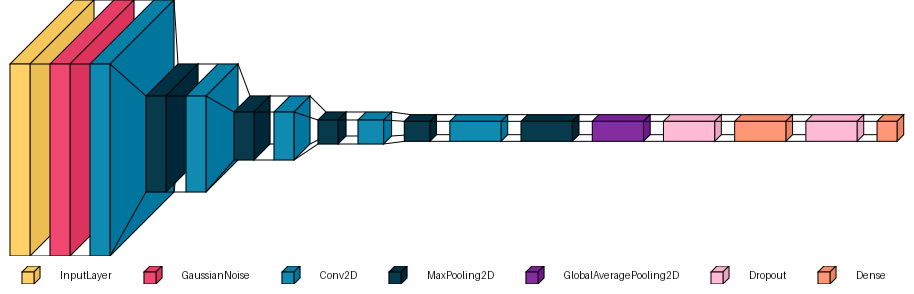

In [43]:
#Graphical representation of the Model
visualkeras.layered_view(model, legend=True, spacing=20, scale_xy=2)

### 🧠 Train the Model

In [44]:
# Create folders and callbacks
callbacks = create_folders_and_callbacks(model_name=MODEL_NAME)


In [45]:
history = model.fit(
    x = train_dataset_mixaug,
    epochs = EPOCHS,
    validation_data = val_dataset,
   callbacks=[callbacks]
).history

Epoch 1/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 146s 330ms/step - accuracy: 0.2948 - loss: 9.9871 - val_accuracy: 0.7216 - val_loss: 1.8514
Epoch 2/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 67s 198ms/step - accuracy: 0.5766 - loss: 1.9063 - val_accuracy: 0.7349 - val_loss: 1.1681
Epoch 3/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 83s 201ms/step - accuracy: 0.6702 - loss: 1.2115 - val_accuracy: 0.7634 - val_loss: 0.8567
Epoch 4/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 70s 208ms/step - accuracy: 0.7093 - loss: 1.0417 - val_accuracy: 0.8186 - val_loss: 0.7410
Epoch 5/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 71s 210ms/step - accuracy: 0.7150 - loss: 0.9923 - val_accuracy: 0.8278 - val_loss: 0.6516
Epoch 6/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 81s 207ms/step - accuracy: 0.7436 - loss: 0.9079 - val_accuracy: 0.8528 - val_loss: 0.6598
Epoch 7/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 70s 207ms/step - accuracy: 0.7735 - loss: 0.8181 - val_accuracy: 0.8570 - val_loss: 0.6596
Epoch 8/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 69s 202ms/step - accuracy: 0.7914 

In [46]:
save_model_weights(model, 'weights_mixaug.keras')

Model weights saved as weights_mixaug.keras


In [47]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

Final validation accuracy: 96.66%


### 📈 Plot the Training History

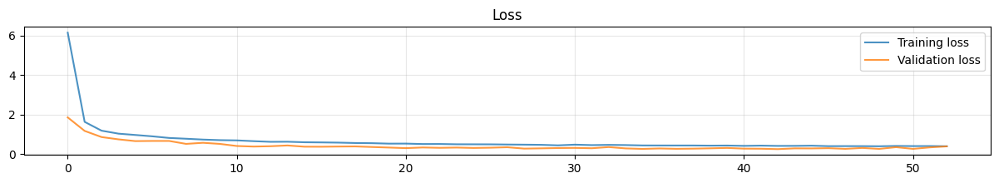

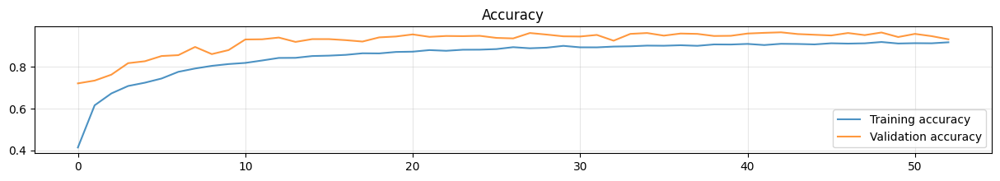

In [48]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

#### Plot confusion matrix for the training set

Accuracy score over the val set: 0.9097
Precision score over the val set: 0.917
Recall score over the val set: 0.9097
F1 score over the val set: 0.9111


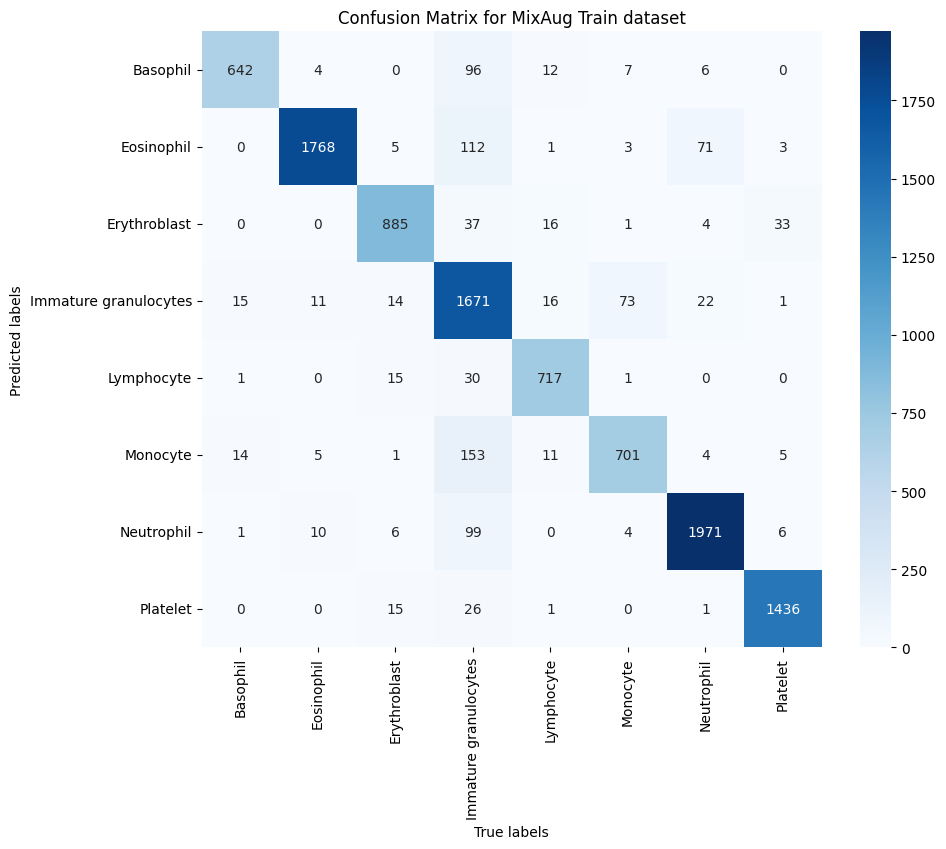

In [49]:
plot_confusion_matrix_for_dataset(train_dataset_mixaug, model, labels, title='Confusion Matrix for MixAug Train dataset')

#### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.9666
Precision score over the val set: 0.967
Recall score over the val set: 0.9666
F1 score over the val set: 0.9664


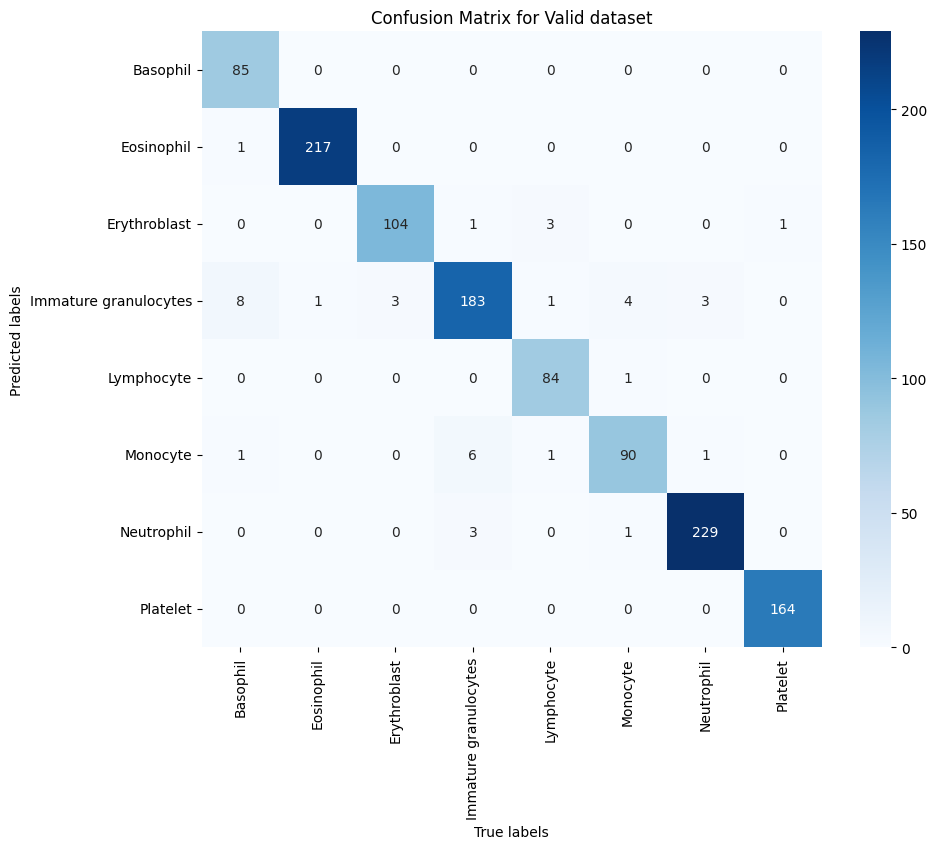

In [50]:
plot_confusion_matrix_for_dataset(val_dataset, model, labels, title='Confusion Matrix for Valid dataset')

# 🛞 Transfer Learning

## 🌟 Final Model

### Supernet: VGG16

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, 96, 96, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, 96, 96, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, 48, 48, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, 48, 48, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, 48, 48, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, 24, 24, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, 24, 24, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, 24, 24, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, 24, 24, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, 12, 12, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, 12, 12, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, 12, 12, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, 6, 6, 512)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, 6, 6, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, 6, 6, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, 6, 6, 512)           │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, 3, 3, 512)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

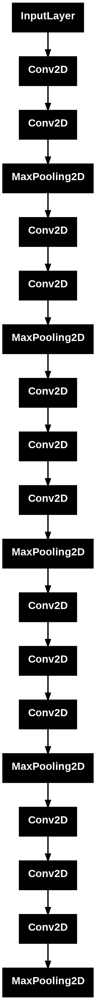

In [ ]:
# Download and plot the VGG16 model
supernet_VGG16 = tfk.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape= INPUT_SHAPE
)

# Plot the model
supernet_VGG16.summary()
tfk.utils.plot_model(supernet_VGG16)

#### 🛠️ Rebuild the Classifier

Rebuild the Top (i.e. Classifier)

In [ ]:
# Use the supernet_VGG16 as feature extractor
supernet_VGG16.trainable = False

# Rebuild the classifier
inputs = tfk.Input(shape=INPUT_SHAPE)
x = supernet_VGG16(inputs)
x = tfkl.GlobalAveragePooling2D()(x)
x = tfkl.Dense(256, kernel_initializer = tfk.initializers.HeUniform(seed))(x)
x = tfkl.BatchNormalization()(x)
x = tfkl.ReLU()(x)
x = tfkl.Dropout(0.35, seed=seed)(x)
x = tfkl.Dense(128, kernel_initializer = tfk.initializers.HeUniform(seed))(x)
x = tfkl.ReLU()(x)
x = tfkl.Dropout(0.2, seed=seed)(x)
outputs = tfkl.Dense(
    NUM_CLASSES,
    activation='softmax',
    kernel_initializer = tfk.initializers.HeUniform(seed))(x)

# Connect input and output through the Model class
model = tfk.Model(inputs=inputs, outputs=outputs, name='model')

# Compile the model
model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 3, 3, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_1 (ReLU)                       │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │           1,032 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,880,968 (56.77 MB)

 Trainable params: 165,768 (647.53 KB)

 Non-trainable params: 14,715,200 (56.13 MB)

In [ ]:
# Set all VGG layers to True
model.get_layer('vgg16').trainable = True
for i, layer in enumerate(model.get_layer('vgg16').layers):
   print(i, layer.name, layer.trainable)

0 input_layer True
1 block1_conv1 True
2 block1_conv2 True
3 block1_pool True
4 block2_conv1 True
5 block2_conv2 True
6 block2_pool True
7 block3_conv1 True
8 block3_conv2 True
9 block3_conv3 True
10 block3_pool True
11 block4_conv1 True
12 block4_conv2 True
13 block4_conv3 True
14 block4_pool True
15 block5_conv1 True
16 block5_conv2 True
17 block5_conv3 True
18 block5_pool True


#### 🎚️ Fine tuning

Freeze the first 16 layers of VGG16 \\
SET TRAINABLE LAYER
> total layers: 19 \\
> trainable layers: 16 \\
> Non Trainable Par: 3

In [ ]:
# Freeze the first 3 layers
for i, layer in enumerate(model.get_layer('vgg16').layers[:3]):
  layer.trainable=False

print()
for i, layer in enumerate(model.get_layer('vgg16').layers):
   print(i, layer.name, layer.trainable)
model.summary()



0 input_layer False
1 block1_conv1 False
2 block1_conv2 False
3 block1_pool True
4 block2_conv1 True
5 block2_conv2 True
6 block2_pool True
7 block3_conv1 True
8 block3_conv2 True
9 block3_conv3 True
10 block3_pool True
11 block4_conv1 True
12 block4_conv2 True
13 block4_conv3 True
14 block4_pool True
15 block5_conv1 True
16 block5_conv2 True
17 block5_conv3 True
18 block5_pool True


Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 3, 3, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_1 (ReLU)                       │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │           1,032 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,880,968 (56.77 MB)

 Trainable params: 14,841,736 (56.62 MB)

 Non-trainable params: 39,232 (153.25 KB)

In [ ]:
# Create folders and callbacks
callbacks = create_folders_and_callbacks(model_name=MODEL_NAME)

# Train the model
history = model.fit(
    x = train_dataset_aug,
    batch_size = BATCH_SIZE,
    epochs = EPOCHS,
    validation_data = val_dataset_with_noise,
    callbacks=[callbacks]
).history

Epoch 1/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 116s 295ms/step - accuracy: 0.5491 - loss: 1.3245 - val_accuracy: 0.8378 - val_loss: 0.4957
Epoch 2/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 91s 270ms/step - accuracy: 0.8776 - loss: 0.3704 - val_accuracy: 0.8018 - val_loss: 0.7824
Epoch 3/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 139s 262ms/step - accuracy: 0.9148 - loss: 0.2705 - val_accuracy: 0.9089 - val_loss: 0.3456
Epoch 4/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 145s 270ms/step - accuracy: 0.9272 - loss: 0.2223 - val_accuracy: 0.8503 - val_loss: 0.4871
Epoch 5/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 91s 268ms/step - accuracy: 0.9296 - loss: 0.2155 - val_accuracy: 0.9264 - val_loss: 0.2533
Epoch 6/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 141s 268ms/step - accuracy: 0.9360 - loss: 0.1841 - val_accuracy: 0.9398 - val_loss: 0.1728
Epoch 7/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 140s 262ms/step - accuracy: 0.9445 - loss: 0.1736 - val_accuracy: 0.9164 - val_loss: 0.2486
Epoch 8/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 142s 263ms/step - accuracy: 0.

In [ ]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

Final validation accuracy: 96.32%


In [ ]:
save_model_weights(model, 'VGG16_weights_freez3.keras')

Model weights saved as VGG16_weights_freez3.keras


#### 📈 Plot the Training History

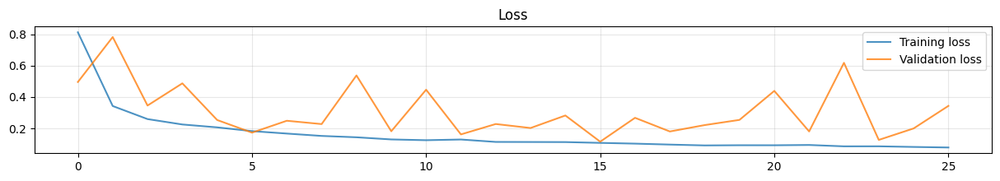

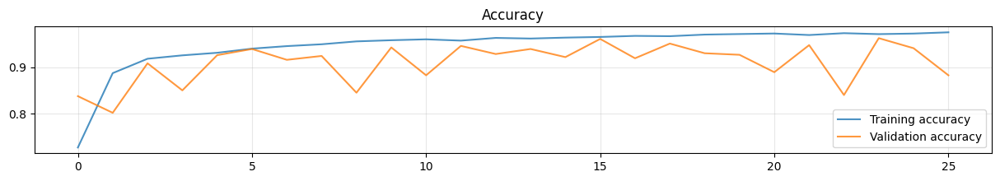

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

##### Plot confusion matrix for the trainning set

Accuracy score over the val set: 0.9705
Precision score over the val set: 0.9712
Recall score over the val set: 0.9705
F1 score over the val set: 0.9705


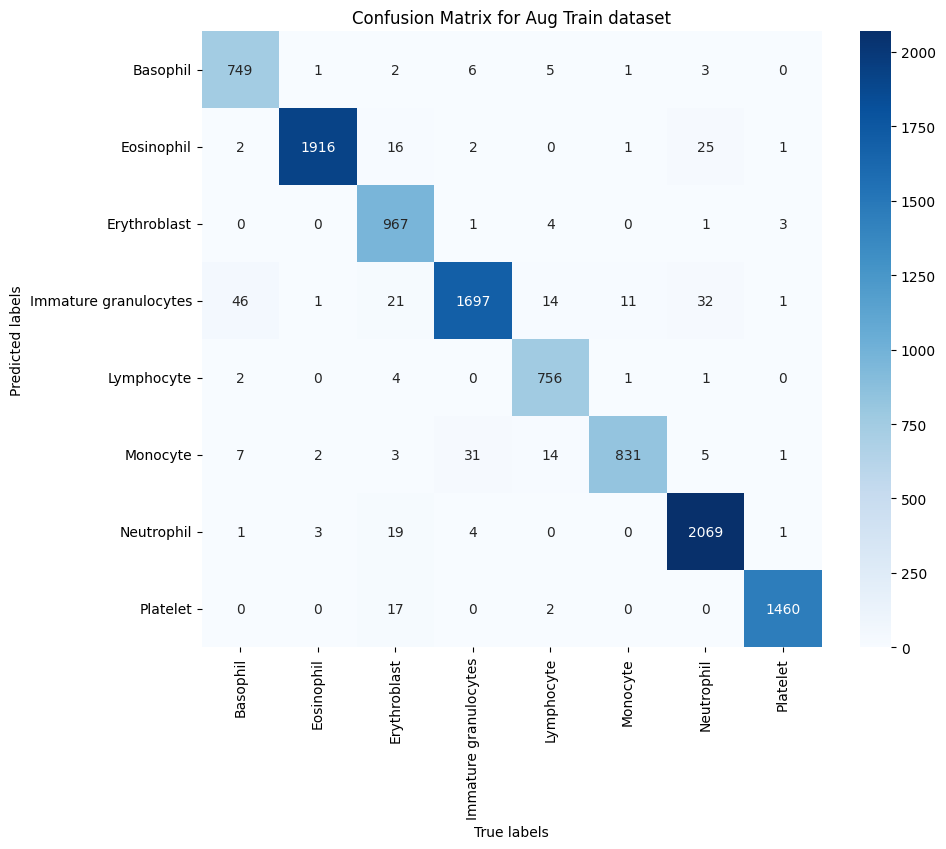

In [ ]:
# Plot confusion matrix for train_gen, mixaug_gen, randaug_gen
# plot_confusion_matrix_for_dataset(train_dataset, model, labels, title='Confusion Matrix for Train dataset')
# plot_confusion_matrix_for_dataset(train_dataset_mixaug, model, labels, title='Confusion Matrix for MixAug dataset')
# plot_confusion_matrix_for_dataset(train_dataset_randaug, model, labels, title='Confusion Matrix for RandAug dataset')
plot_confusion_matrix_for_dataset(train_dataset_aug, model, labels, title='Confusion Matrix for Aug Train dataset')
#plot_confusion_matrix_for_dataset(train_dataset_aug_with_noise, model, labels, title='Confusion Matrix for Aug Train dataset with WN ')

##### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.9615
Precision score over the val set: 0.9622
Recall score over the val set: 0.9615
F1 score over the val set: 0.9612


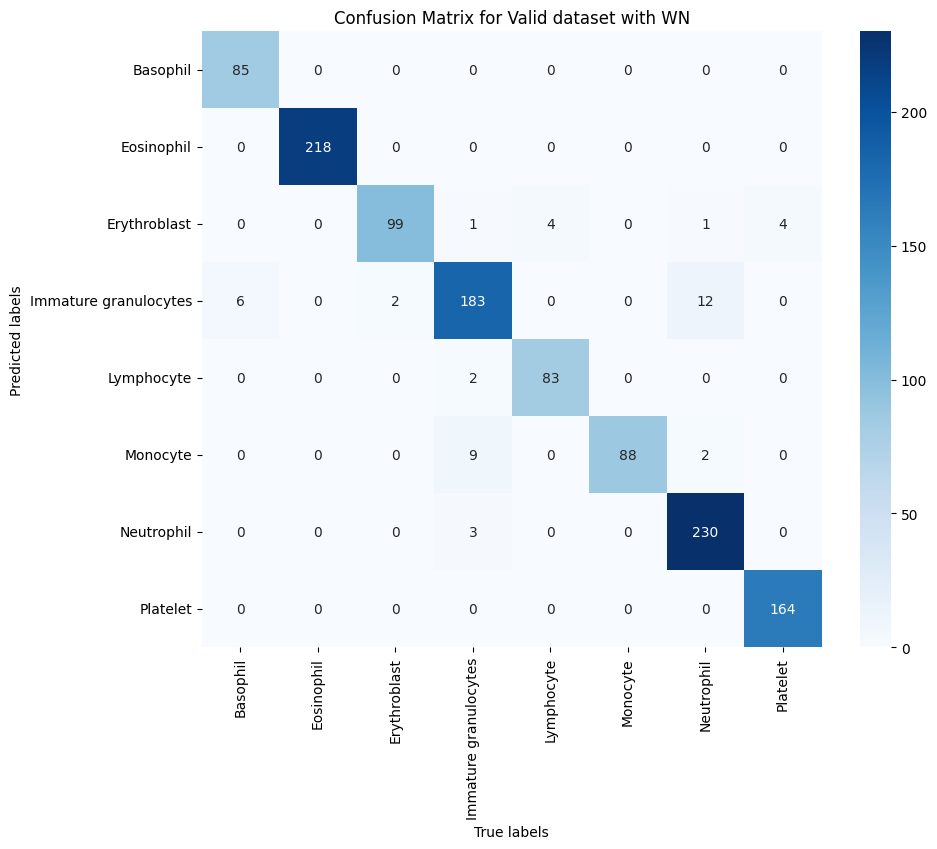

In [ ]:
plot_confusion_matrix_for_dataset(val_dataset_with_noise, model, labels, title='Confusion Matrix for Valid dataset with WN')

## 🗂️ Other Models

### Supernet: ResNet50V2

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "resnet50v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 96, 96, 3)      │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_pad (ZeroPadding2D) │ (None, 102, 102, 3)    │              0 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 48, 48, 64)     │          9,472 │ conv1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pad (ZeroPadding2D) │ (None, 50, 50, 64)     │              0 │ conv1_conv[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pool (MaxPooling2D) │ (None, 24, 24, 64)     │              0 │ pool1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_preact_bn    │ (None, 24, 24, 64)     │            256 │ pool1_pool[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_preact_relu  │ (None, 24, 24, 64)     │              0 │ conv2_block1_preact_b… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 24, 24, 64)     │          4,096 │ conv2_block1_preact_r… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 24, 24, 64)     │            256 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 24, 24, 64)     │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_pad        │ (None, 26, 26, 64)     │              0 │ conv2_block1_1_relu[0… │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 24, 24, 64)     │         36,864 │ conv2_block1_2_pad[0]… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_bn         │ (None, 24, 24, 64)     │            256 │ conv2_block1_2_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_relu       │ (None, 24, 24, 64)     │              0 │ conv2_block1_2_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_conv       │ (None, 24, 24, 256)    │         16,640 │ conv2_block1_preact_r… │
│ (Conv2D)             

 Total params: 23,564,800 (89.89 MB)

 Trainable params: 23,519,360 (89.72 MB)

 Non-trainable params: 45,440 (177.50 KB)




In [ ]:
supernet_ResNet50V2= tfk.applications.ResNet50V2(
    include_top=False,
    weights="imagenet",
    input_shape=INPUT_SHAPE,
)

supernet_ResNet50V2 .summary()
# Display model architecture with layer shapes and trainable parameters
tfk.utils.plot_model(supernet_ResNet50V2 , expand_nested=True, show_trainable=True, show_shapes=True, dpi=70)

#### 🛠️ Rebuild the Classifier

Rebuild the Top (i.e. Classifier)

In [ ]:
# Use the supernet_ResNet50V2 as feature extractor
supernet_ResNet50V2.trainable = False

# Rebuild the classifier
inputs = tfk.Input(shape=INPUT_SHAPE)
x = supernet_ResNet50V2(inputs)
x = tfkl.GlobalAveragePooling2D()(x)
x = tfkl.Dense(256, kernel_initializer = tfk.initializers.HeUniform(seed))(x)
x = tfkl.BatchNormalization()(x)
x = tfkl.ReLU()(x)
outputs = tfkl.Dense(
    NUM_CLASSES,
    activation='softmax',
    kernel_initializer = tfk.initializers.HeUniform(seed))(x)

# Connect input and output through the Model class
model = tfk.Model(inputs=inputs, outputs=outputs, name='model')

# Compile the model
model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50v2 (Functional)              │ (None, 3, 3, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,092,424 (91.91 MB)

 Trainable params: 527,112 (2.01 MB)

 Non-trainable params: 23,565,312 (89.89 MB)

In [ ]:
# Set all EfficientNet layers to True
model.get_layer('resnet50v2').trainable = True
for i, layer in enumerate(model.get_layer('resnet50v2').layers):
   print(i, layer.name, layer.trainable)

0 input_layer True
1 conv1_pad True
2 conv1_conv True
3 pool1_pad True
4 pool1_pool True
5 conv2_block1_preact_bn True
6 conv2_block1_preact_relu True
7 conv2_block1_1_conv True
8 conv2_block1_1_bn True
9 conv2_block1_1_relu True
10 conv2_block1_2_pad True
11 conv2_block1_2_conv True
12 conv2_block1_2_bn True
13 conv2_block1_2_relu True
14 conv2_block1_0_conv True
15 conv2_block1_3_conv True
16 conv2_block1_out True
17 conv2_block2_preact_bn True
18 conv2_block2_preact_relu True
19 conv2_block2_1_conv True
20 conv2_block2_1_bn True
21 conv2_block2_1_relu True
22 conv2_block2_2_pad True
23 conv2_block2_2_conv True
24 conv2_block2_2_bn True
25 conv2_block2_2_relu True
26 conv2_block2_3_conv True
27 conv2_block2_out True
28 conv2_block3_preact_bn True
29 conv2_block3_preact_relu True
30 conv2_block3_1_conv True
31 conv2_block3_1_bn True
32 conv2_block3_1_relu True
33 conv2_block3_2_pad True
34 conv2_block3_2_conv True
35 conv2_block3_2_bn True
36 conv2_block3_2_relu True
37 max_pooling2d 

#### 🎚️ Fine tuning

Freeze the first 16 layers of ResNet

In [ ]:
# Freeze the first 16 layers
for i, layer in enumerate(model.get_layer('resnet50v2').layers[:16]):
  layer.trainable=False

print()
for i, layer in enumerate(model.get_layer('resnet50v2').layers):
   print(i, layer.name, layer.trainable)
model.summary()



0 input_layer False
1 conv1_pad False
2 conv1_conv False
3 pool1_pad False
4 pool1_pool False
5 conv2_block1_preact_bn False
6 conv2_block1_preact_relu False
7 conv2_block1_1_conv False
8 conv2_block1_1_bn False
9 conv2_block1_1_relu False
10 conv2_block1_2_pad False
11 conv2_block1_2_conv False
12 conv2_block1_2_bn False
13 conv2_block1_2_relu False
14 conv2_block1_0_conv False
15 conv2_block1_3_conv False
16 conv2_block1_out True
17 conv2_block2_preact_bn True
18 conv2_block2_preact_relu True
19 conv2_block2_1_conv True
20 conv2_block2_1_bn True
21 conv2_block2_1_relu True
22 conv2_block2_2_pad True
23 conv2_block2_2_conv True
24 conv2_block2_2_bn True
25 conv2_block2_2_relu True
26 conv2_block2_3_conv True
27 conv2_block2_out True
28 conv2_block3_preact_bn True
29 conv2_block3_preact_relu True
30 conv2_block3_1_conv True
31 conv2_block3_1_bn True
32 conv2_block3_1_relu True
33 conv2_block3_2_pad True
34 conv2_block3_2_conv True
35 conv2_block3_2_bn True
36 conv2_block3_2_relu True


Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50v2 (Functional)              │ (None, 3, 3, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,092,424 (91.91 MB)

 Trainable params: 23,962,376 (91.41 MB)

 Non-trainable params: 130,048 (508.00 KB)

In [ ]:
# Compile the model
model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50v2 (Functional)              │ (None, 3, 3, 2048)          │      23,564,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                         │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,092,424 (91.91 MB)

 Trainable params: 23,962,376 (91.41 MB)

 Non-trainable params: 130,048 (508.00 KB)

In [ ]:
# Create folders and callbacks
callbacks = create_folders_and_callbacks(model_name=MODEL_NAME)

# Train the model
history = model.fit(
    x = train_dataset_mixaug,
    batch_size = BATCH_SIZE,
    epochs = EPOCHS,
    validation_data = val_dataset_with_noise,
    callbacks=[callbacks]
).history

Epoch 1/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 182s 389ms/step - accuracy: 0.6341 - loss: 1.0442 - val_accuracy: 0.8570 - val_loss: 0.4521
Epoch 2/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 105s 309ms/step - accuracy: 0.8803 - loss: 0.3602 - val_accuracy: 0.9373 - val_loss: 0.2056
Epoch 3/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 111s 328ms/step - accuracy: 0.9217 - loss: 0.2337 - val_accuracy: 0.9473 - val_loss: 0.1924
Epoch 4/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 106s 315ms/step - accuracy: 0.9377 - loss: 0.1781 - val_accuracy: 0.9156 - val_loss: 0.2601
Epoch 5/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 145s 324ms/step - accuracy: 0.9512 - loss: 0.1505 - val_accuracy: 0.9331 - val_loss: 0.2505
Epoch 6/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 144s 330ms/step - accuracy: 0.9543 - loss: 0.1337 - val_accuracy: 0.9498 - val_loss: 0.1886
Epoch 7/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 111s 330ms/step - accuracy: 0.9645 - loss: 0.1052 - val_accuracy: 0.9574 - val_loss: 0.1409
Epoch 8/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 114s 336ms/step - accuracy: 

In [ ]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

Final validation accuracy: 96.15%


In [ ]:
save_model_weights(model, 'ResNet50V2_weights_freez16_v2.keras')

Model weights saved as ResNet50V2_weights_freez16_v2.keras


#### 📈 Plot the Training History

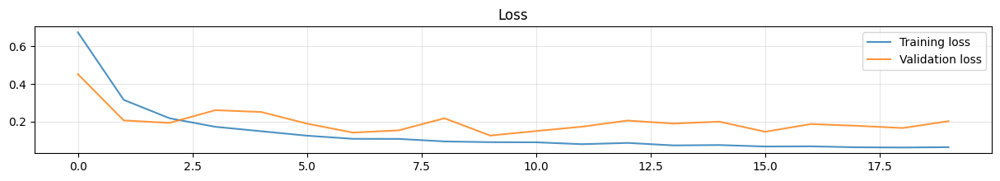

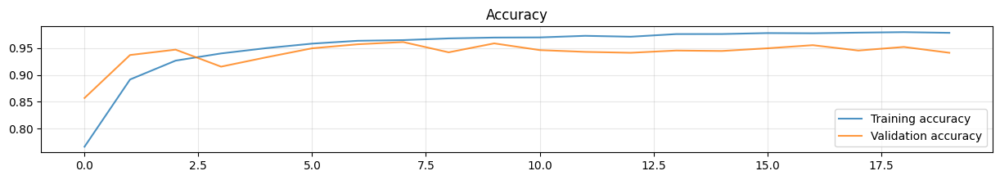

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

##### Plot confusion matrix for the trainning set

Accuracy score over the val set: 0.974
Precision score over the val set: 0.9743
Recall score over the val set: 0.974
F1 score over the val set: 0.974


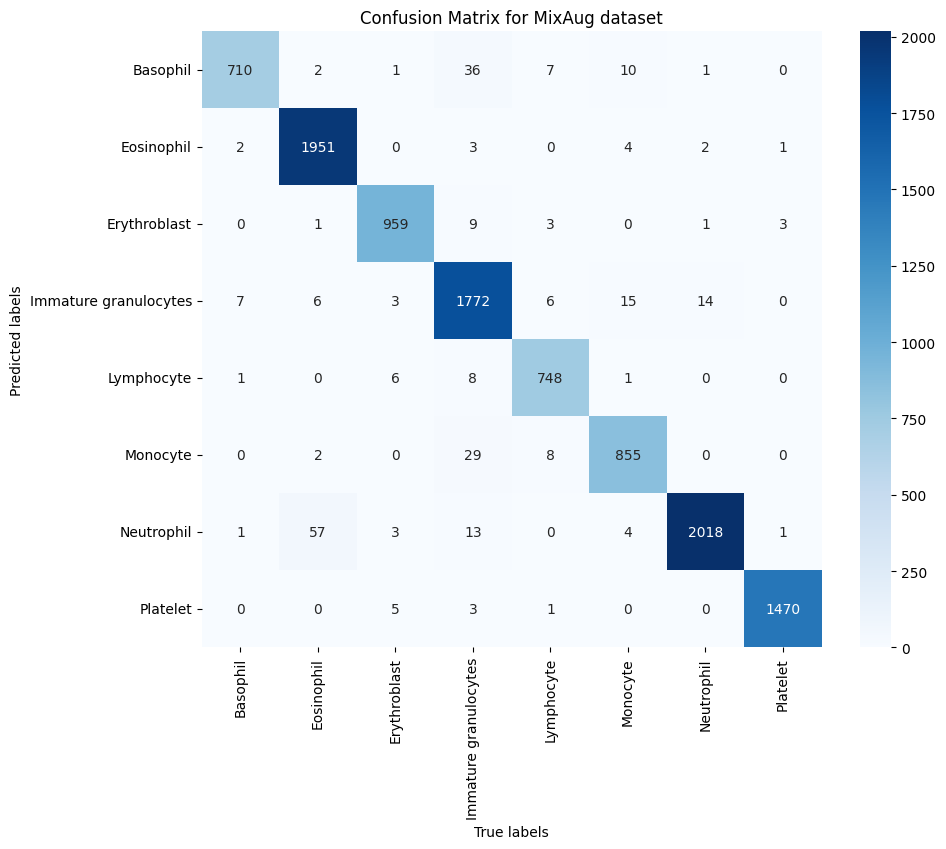

In [ ]:
# Plot confusion matrix for train_gen, mixaug_gen, randaug_gen
# plot_confusion_matrix_for_dataset(train_dataset, model, labels, title='Confusion Matrix for Train dataset')
plot_confusion_matrix_for_dataset(train_dataset_mixaug, model, labels, title='Confusion Matrix for MixAug dataset')
# plot_confusion_matrix_for_dataset(train_dataset_randaug, model, labels, title='Confusion Matrix for RandAug dataset')

##### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.959
Precision score over the val set: 0.9602
Recall score over the val set: 0.959
F1 score over the val set: 0.959


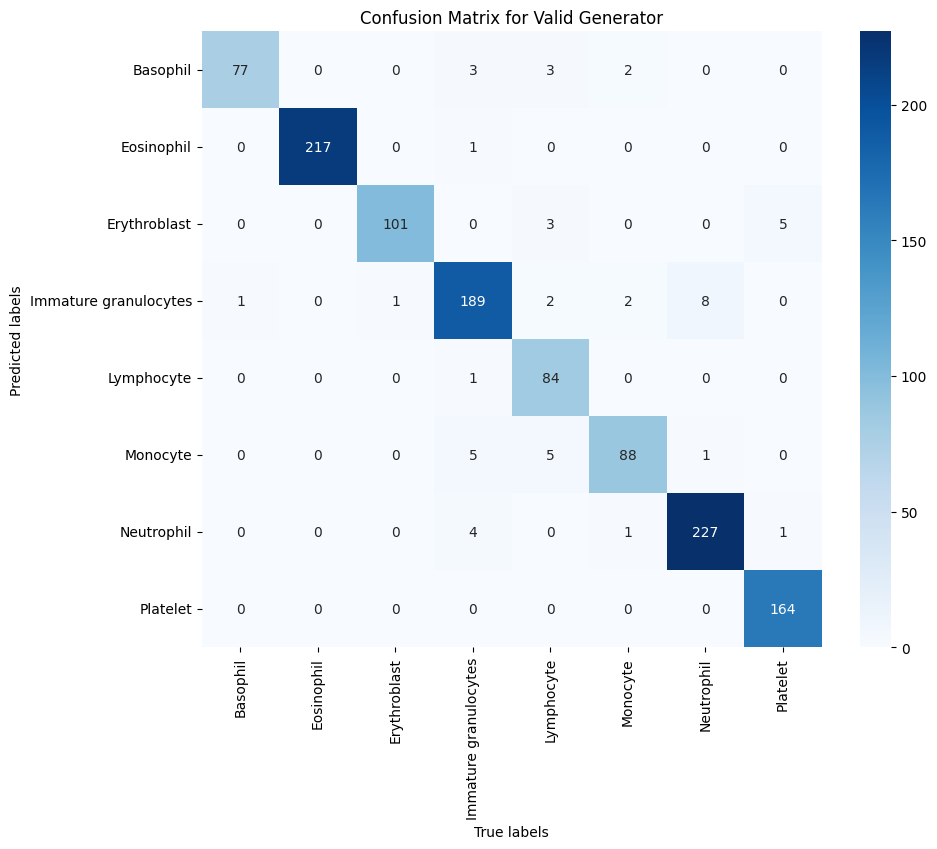

In [ ]:
plot_confusion_matrix_for_dataset(val_dataset, model, labels, title='Confusion Matrix for Valid Generator')

### Supernet: EfficientNetB0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5             │ (None, 96, 96, 3)      │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ rescaling_4 (Rescaling)   │ (None, 96, 96, 3)      │              0 │ input_layer_5[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ normalization_2           │ (None, 96, 96, 3)      │              7 │ rescaling_4[0][0]      │
│ (Normalization)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ rescaling_5 (Rescaling)   │ (None, 96, 96, 3)      │              0 │ normalization_2[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_conv_pad             │ (None, 97, 97, 3)      │              0 │ rescaling_5[0][0]      │
│ (ZeroPadding2D)           │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_conv (Conv2D)        │ (None, 48, 48, 32)     │            864 │ stem_conv_pad[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_bn                   │ (None, 48, 48, 32)     │            128 │ stem_conv[0][0]        │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ stem_activation           │ (None, 48, 48, 32)     │              0 │ stem_bn[0][0]          │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_dwconv            │ (None, 48, 48, 32)     │            288 │ stem_activation[0][0]  │
│ (DepthwiseConv2D)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_bn                │ (None, 48, 48, 32)     │            128 │ block1a_dwconv[0][0]   │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_activation        │ (None, 48, 48, 32)     │              0 │ block1a_bn[0][0]       │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_squeeze        │ (None, 32)             │              0 │ block1a_activation[0]… │
│ (GlobalAveragePooling2D)  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_reshape        │ (None, 1, 1, 32)       │              0 │ block1a_se_squeeze[0]… │
│ (Reshape)                 │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ block1a_se_reduce         │ (None, 1, 1, 8)        │            264 │ block1a_se_reshape[0]… │
│ (Conv2D)                  │                        │                │                        │
├──────────────────────

 Total params: 4,049,571 (15.45 MB)

 Trainable params: 4,007,548 (15.29 MB)

 Non-trainable params: 42,023 (164.16 KB)

dot: graph is too large for cairo-renderer bitmaps. Scaling by 0.612788 to fit






In [ ]:
# Download and plot the EfficientNet B0 model
supernet_EffNetB0 = tfk.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape= INPUT_SHAPE
)

# Plot the model
supernet_EffNetB0.summary()
tfk.utils.plot_model(supernet_EffNetB0)

#### 🛠️ Rebuild the Classifier

Rebuild the Top (i.e. Classifier)

In [ ]:
# Use the pretrainedEffNet as feature extractor
supernet_EffNetB0.trainable = False

# Rebuild the classifier
inputs = tfk.Input(shape=INPUT_SHAPE)
x = supernet_EffNetB0(inputs)
x = tfkl.GlobalAveragePooling2D()(x)
x = tfkl.Dense(256, kernel_initializer = tfk.initializers.HeUniform(seed))(x)
x = tfkl.BatchNormalization()(x)
x = tfkl.ReLU()(x)
outputs = tfkl.Dense(
    NUM_CLASSES,
    activation='softmax',
    kernel_initializer = tfk.initializers.HeUniform(seed))(x)

# Connect input and output through the Model class
model = tfk.Model(inputs=inputs, outputs=outputs, name='model')

# Compile the model
model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 3, 3, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_3 (ReLU)                       │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,380,587 (16.71 MB)

 Trainable params: 330,504 (1.26 MB)

 Non-trainable params: 4,050,083 (15.45 MB)

In [ ]:
# Set all EfficientNet layers to True
model.get_layer('efficientnetb0').trainable = True
for i, layer in enumerate(model.get_layer('efficientnetb0').layers):
   print(i, layer.name, layer.trainable)


0 input_layer_5 True
1 rescaling_4 True
2 normalization_2 True
3 rescaling_5 True
4 stem_conv_pad True
5 stem_conv True
6 stem_bn True
7 stem_activation True
8 block1a_dwconv True
9 block1a_bn True
10 block1a_activation True
11 block1a_se_squeeze True
12 block1a_se_reshape True
13 block1a_se_reduce True
14 block1a_se_expand True
15 block1a_se_excite True
16 block1a_project_conv True
17 block1a_project_bn True
18 block2a_expand_conv True
19 block2a_expand_bn True
20 block2a_expand_activation True
21 block2a_dwconv_pad True
22 block2a_dwconv True
23 block2a_bn True
24 block2a_activation True
25 block2a_se_squeeze True
26 block2a_se_reshape True
27 block2a_se_reduce True
28 block2a_se_expand True
29 block2a_se_excite True
30 block2a_project_conv True
31 block2a_project_bn True
32 block2b_expand_conv True
33 block2b_expand_bn True
34 block2b_expand_activation True
35 block2b_dwconv True
36 block2b_bn True
37 block2b_activation True
38 block2b_se_squeeze True
39 block2b_se_reshape True
40 b

Freeze the first 162 layers of EfficientNet

#### 🎚️ Fine tuning

In [ ]:
# Freeze the first 162 layers
for i, layer in enumerate(model.get_layer('efficientnetb0').layers[:162]):
  layer.trainable=False

print()
for i, layer in enumerate(model.get_layer('efficientnetb0').layers):
   print(i, layer.name, layer.trainable)
model.summary()



0 input_layer_5 False
1 rescaling_4 False
2 normalization_2 False
3 rescaling_5 False
4 stem_conv_pad False
5 stem_conv False
6 stem_bn False
7 stem_activation False
8 block1a_dwconv False
9 block1a_bn False
10 block1a_activation False
11 block1a_se_squeeze False
12 block1a_se_reshape False
13 block1a_se_reduce False
14 block1a_se_expand False
15 block1a_se_excite False
16 block1a_project_conv False
17 block1a_project_bn False
18 block2a_expand_conv False
19 block2a_expand_bn False
20 block2a_expand_activation False
21 block2a_dwconv_pad False
22 block2a_dwconv False
23 block2a_bn False
24 block2a_activation False
25 block2a_se_squeeze False
26 block2a_se_reshape False
27 block2a_se_reduce False
28 block2a_se_expand False
29 block2a_se_excite False
30 block2a_project_conv False
31 block2a_project_bn False
32 block2b_expand_conv False
33 block2b_expand_bn False
34 block2b_expand_activation False
35 block2b_dwconv False
36 block2b_bn False
37 block2b_activation False
38 block2b_se_squee

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 3, 3, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_3 (ReLU)                       │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,380,587 (16.71 MB)

 Trainable params: 3,486,244 (13.30 MB)

 Non-trainable params: 894,343 (3.41 MB)

In [ ]:
# Compile the model
model.compile(loss=tfk.losses.CategoricalCrossentropy(), optimizer=tfk.optimizers.Adam(learning_rate=LEARNING_RATE), metrics=['accuracy'])
model.summary()

Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 3, 3, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ re_lu_3 (ReLU)                       │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,380,587 (16.71 MB)

 Trainable params: 3,486,244 (13.30 MB)

 Non-trainable params: 894,343 (3.41 MB)

In [ ]:
# Create folders and callbacks
callbacks = create_folders_and_callbacks(model_name=MODEL_NAME)

# Train the model
history = model.fit(
    x = train_dataset_mixaug,
    batch_size = BATCH_SIZE,
    epochs = EPOCHS,
    validation_data = val_dataset,
    callbacks=[callbacks]
).history

Epoch 1/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 161s 364ms/step - accuracy: 0.1616 - loss: 2.1982 - val_accuracy: 0.1948 - val_loss: 2.0719
Epoch 2/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 97s 283ms/step - accuracy: 0.2099 - loss: 2.0160 - val_accuracy: 0.1890 - val_loss: 2.0156
Epoch 3/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 144s 289ms/step - accuracy: 0.2084 - loss: 1.9762 - val_accuracy: 0.1856 - val_loss: 2.0360
Epoch 4/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 136s 272ms/step - accuracy: 0.2384 - loss: 1.9335 - val_accuracy: 0.1697 - val_loss: 1.9843
Epoch 5/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 147s 289ms/step - accuracy: 0.2384 - loss: 1.9213 - val_accuracy: 0.3035 - val_loss: 1.9247
Epoch 6/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 137s 272ms/step - accuracy: 0.2510 - loss: 1.8903 - val_accuracy: 0.2266 - val_loss: 1.9598
Epoch 7/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 145s 283ms/step - accuracy: 0.2534 - loss: 1.8803 - val_accuracy: 0.4540 - val_loss: 1.9181
Epoch 8/100
337/337 ━━━━━━━━━━━━━━━━━━━━ 93s 274ms/step - accuracy: 0.

In [ ]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

Final validation accuracy: 45.4%


In [ ]:
save_model_weights(model, 'EfficientNetB0_weights.keras')

Model weights saved as EfficientNetB0_weights.keras


#### 📈 Plot the Training History

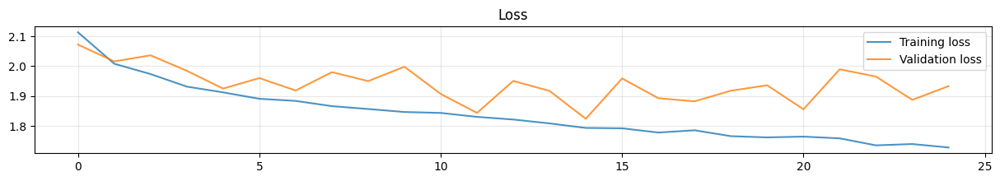

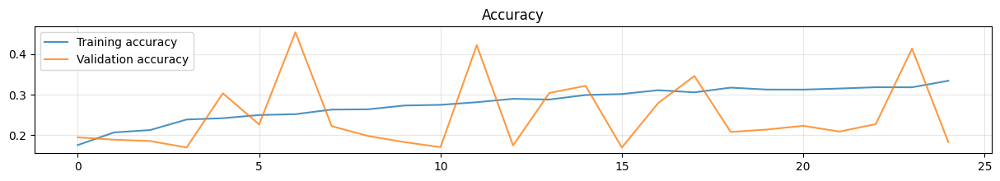

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

##### Plot confusion matrix for the trainning set

Accuracy score over the val set: 0.2145
Precision score over the val set: 0.1896
Recall score over the val set: 0.2145
F1 score over the val set: 0.1203


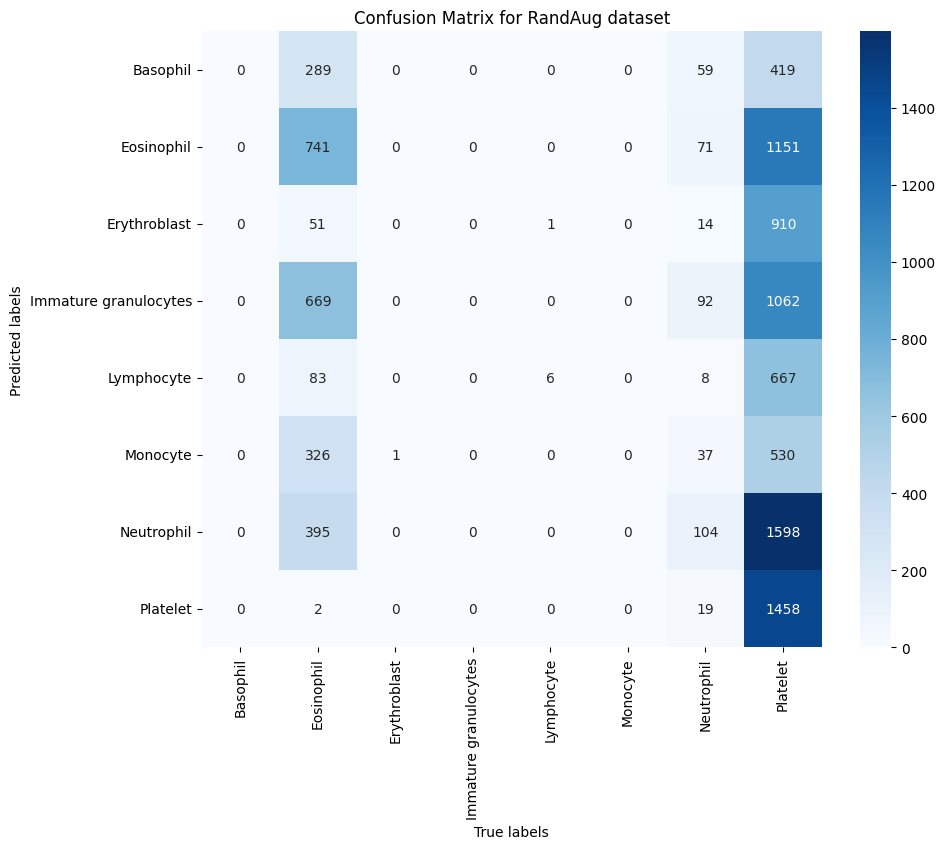

In [ ]:
# Plot confusion matrix for train_gen, mixaug_gen, randaug_gen
# plot_confusion_matrix_for_dataset(train_dataset, model, labels, title='Confusion Matrix for Train dataset')
plot_confusion_matrix_for_dataset(train_dataset_mixaug, model, labels, title='Confusion Matrix for RandAug dataset')

##### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.3219
Precision score over the val set: 0.1645
Recall score over the val set: 0.3219
F1 score over the val set: 0.175


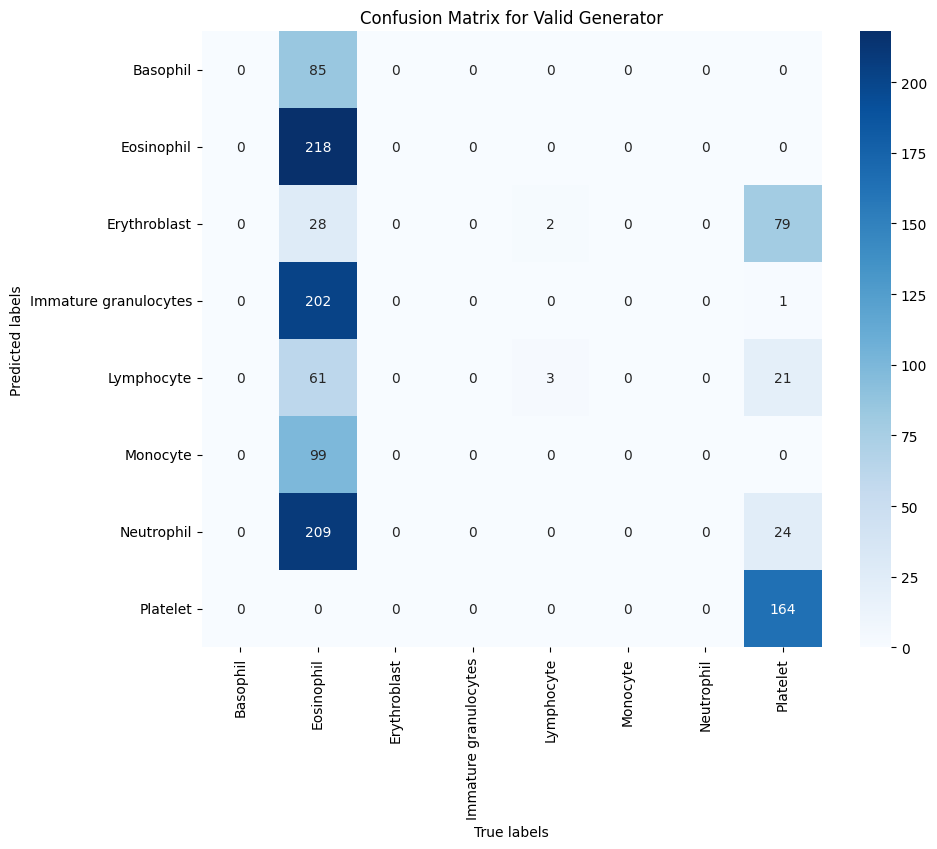

In [ ]:
plot_confusion_matrix_for_dataset(val_dataset, model, labels, title='Confusion Matrix for Valid Generator')

### Supernet: InceptionV3

In [ ]:
backbone = tfk.applications.InceptionV3(
    include_top=False,
    weights="imagenet",
    input_shape=INPUT_SHAPE,
    name="inception_v3",
)
backbone.summary()
# Display model architecture with layer shapes and trainable parameters
tfk.utils.plot_model(backbone, expand_nested=True, show_trainable=True, show_shapes=True, dpi=70)

#### 🛠️ Rebuild the Classifier

Rebuild the Top (i.e. Classifier)

In [ ]:
seed = seed


# Freeze the weights of the base model (no training)
backbone.trainable = False


# Input layer
inputs = tfk.Input(shape=INPUT_SHAPE)
x = tfkl.Rescaling(scale=1.0/127.5, offset=-1, name='Preprocessing')(inputs)
x = augmentation(x)
# Feature extraction
x = backbone(x)

gap_layer = tfkl.GlobalAveragePooling2D(name='GlobalAVGPool')(x)

dropout1 = tfkl.Dropout(0.3, seed=seed, name='first_Dropout')(gap_layer)
classifier_layer = tfkl.Dense(
    units=256,
    kernel_initializer=tf.keras.initializers.HeUniform(seed=seed),
    activation='relu',
    name='Dense_Classifier'
)(dropout1)
dropout2 = tfkl.Dropout(0.3, seed=seed, name='second_Dropout')(classifier_layer)
output_layer = tfkl.Dense(
    units=8,
    activation='softmax',
    kernel_initializer=tf.keras.initializers.HeUniform(seed=seed),
    name='Output_Dense'
)(dropout2)



# Connect input and output through the Model class
model = tfk.Model(inputs=inputs, outputs=output_layer, name='model')

# Compile the model
model.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(),
    metrics=['accuracy']
)

model.summary()


Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Preprocessing (Rescaling)            │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Augmentation (Sequential)            │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ inception_v3 (Functional)            │ (None, 1, 1, 2048)          │      21,802,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ GlobalAVGPool                        │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ first_Dropout (Dropout)              │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dense_Classifier (Dense)             │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ second_Dropout (Dropout)             │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output_Dense (Dense)                 │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,329,384 (85.18 MB)

 Trainable params: 526,600 (2.01 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
for images, labels in train_dataset.take(1):
    print("Target shape:", labels.shape)
    predictions = model(images)
    print("Output shape:", predictions.shape)


Target shape: (32, 8)
Output shape: (32, 8)


In [ ]:

history = model.fit(
    train_dataset,
    batch_size = BATCH_SIZE,
    epochs = 10,
    validation_data= val_dataset,
    class_weight = class_weights,
    callbacks=tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                                mode='max',
                                                patience=10,
                                                restore_best_weights=True)
).history

Epoch 1/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 285s 824ms/step - accuracy: 0.3264 - loss: 1.7083 - val_accuracy: 0.3972 - val_loss: 1.4517
Epoch 2/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 259s 767ms/step - accuracy: 0.3303 - loss: 1.6851 - val_accuracy: 0.4005 - val_loss: 1.4510
Epoch 3/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 256s 757ms/step - accuracy: 0.3416 - loss: 1.6712 - val_accuracy: 0.3963 - val_loss: 1.3888
Epoch 4/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 259s 746ms/step - accuracy: 0.3538 - loss: 1.6279 - val_accuracy: 0.4156 - val_loss: 1.3872
Epoch 5/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 269s 766ms/step - accuracy: 0.3478 - loss: 1.6438 - val_accuracy: 0.4156 - val_loss: 1.3832
Epoch 6/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 262s 775ms/step - accuracy: 0.3531 - loss: 1.6309 - val_accuracy: 0.3746 - val_loss: 1.5212
Epoch 7/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 319s 767ms/step - accuracy: 0.3529 - loss: 1.6417 - val_accuracy: 0.4089 - val_loss: 1.4821
Epoch 8/10
337/337 ━━━━━━━━━━━━━━━━━━━━ 262s 767ms/step - accuracy: 0.3511 -

In [ ]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

model.save('transf_resnet.keras')

Final validation accuracy: 43.23%


#### 📈 Plot the Training History

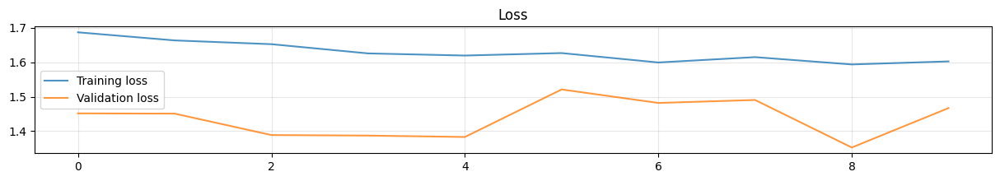

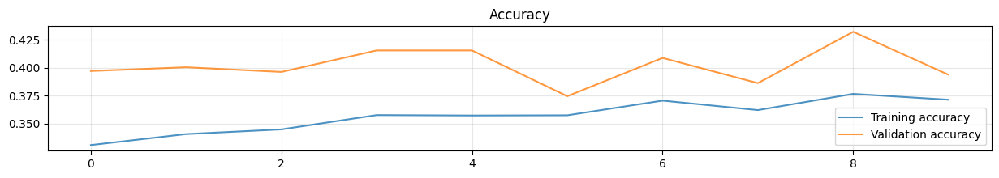

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

##### Plot confusion matrix for the trainning set

Accuracy score over the train set: 0.4269
Precision score over the train set: 0.5826
Recall score over the train set: 0.4269
F1 score over the train set: 0.3817


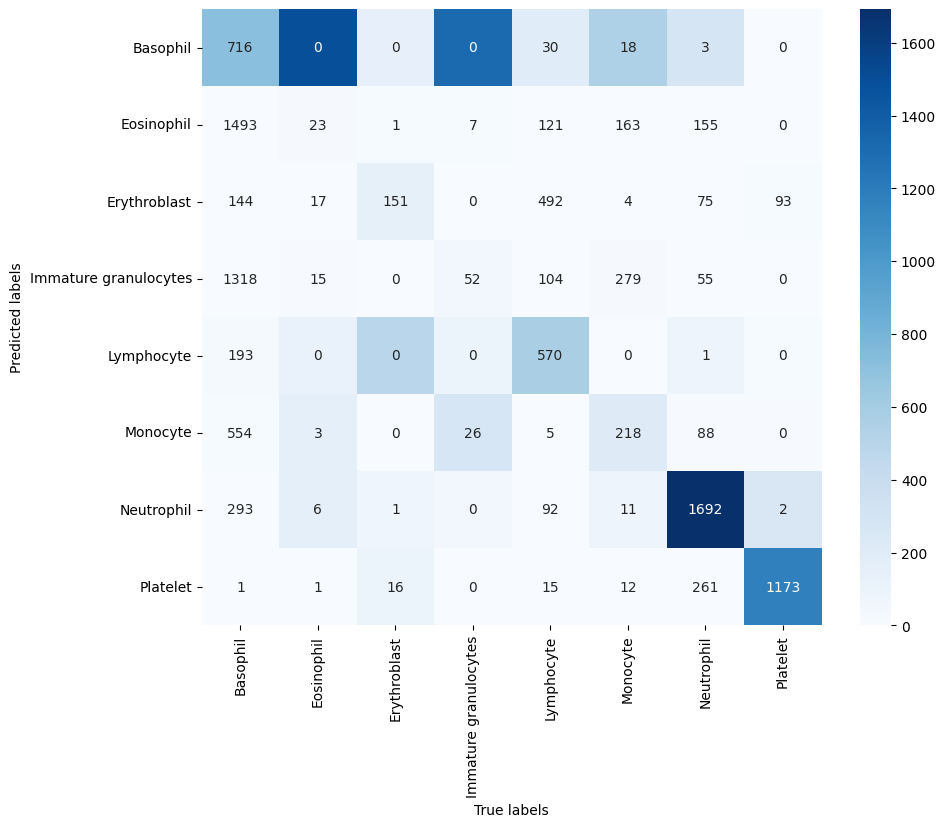

In [ ]:
# Predict the train set
train_predictions = model.predict(X_train, verbose=0)
train_predictions = np.argmax(train_predictions, axis=-1)

# Extract ground truth classes
train_gt = np.argmax(y_train, axis=-1)

train_predictions.shape

#labels
labels = ['Basophil',                    # 0
          'Eosinophil',                  # 1
          'Erythroblast',                # 2
          'Immature granulocytes',       # 3
          'Lymphocyte',                  # 4
          'Monocyte',                    # 5
          'Neutrophil',                  # 6
          'Platelet']                    # 7

# Compute the confusion matrix
cm = confusion_matrix(train_gt, train_predictions)

# Compute the classification metrics
train_accuracy = accuracy_score(train_gt, train_predictions)
train_precision = precision_score(train_gt, train_predictions, average='weighted')
train_recall = recall_score(train_gt, train_predictions, average='weighted')
train_f1 = f1_score(train_gt,train_predictions, average='weighted')
print(f'Accuracy score over the train set: {round(train_accuracy, 4)}')
print(f'Precision score over the train set: {round(train_precision, 4)}')
print(f'Recall score over the train set: {round(train_recall, 4)}')
print(f'F1 score over the train set: {round(train_f1, 4)}')

cm = confusion_matrix(train_gt,train_predictions)

# Create labels combining confusion matrix values
labels_conf = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, annot=labels_conf, fmt='', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

##### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.4323
Precision score over the val set: 0.5405
Recall score over the val set: 0.4323
F1 score over the val set: 0.3788


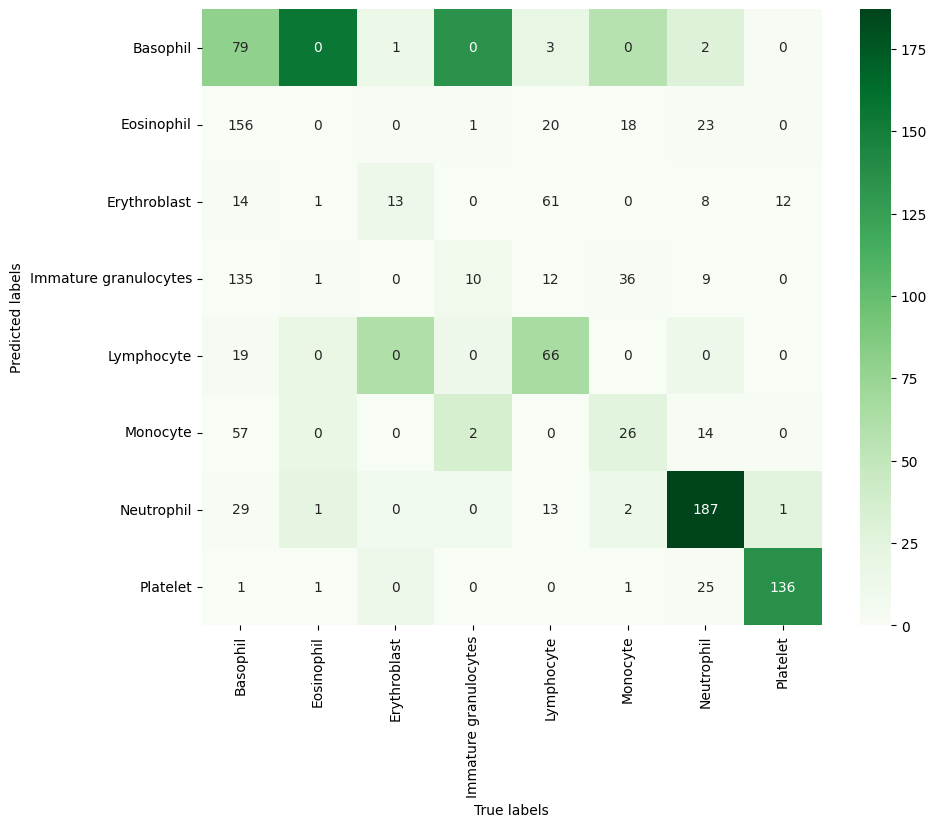

In [ ]:
# Predict the validation set
val_predictions = model.predict(X_val, verbose=0)
val_predictions = np.argmax(val_predictions, axis=-1)

# Extract ground truth classes
val_gt = np.argmax(y_val, axis=-1)

val_predictions.shape

#labels
labels = ['Basophil',                    # 0
          'Eosinophil',                  # 1
          'Erythroblast',                # 2
          'Immature granulocytes',       # 3
          'Lymphocyte',                  # 4
          'Monocyte',                    # 5
          'Neutrophil',                  # 6
          'Platelet']                    # 7

# Compute the confusion matrix
cm = confusion_matrix(val_gt, val_predictions)

# Compute the classification metrics
val_accuracy = accuracy_score(val_gt, val_predictions)
val_precision = precision_score(val_gt, val_predictions, average='weighted')
val_val_recall = recall_score(val_gt, val_predictions, average='weighted')
val_f1 = f1_score(val_gt,val_predictions, average='weighted')
print(f'Accuracy score over the val set: {round(val_accuracy, 4)}')
print(f'Precision score over the val set: {round(val_precision, 4)}')
print(f'Recall score over the val set: {round(val_val_recall, 4)}')
print(f'F1 score over the val set: {round(val_f1, 4)}')

cm = confusion_matrix(val_gt,val_predictions)

# Create labels combining confusion matrix values
labels_conf = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, annot=labels_conf, fmt='', xticklabels=labels, yticklabels=labels, cmap='Greens')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

#### 🎚️ Fine tuning

In [ ]:
# Unreeze the last 100 layers
backbone.trainable = True
for layer in backbone.layers[:-100]:
    layer.trainable = False



Model: "model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Preprocessing (Rescaling)            │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Augmentation (Sequential)            │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ inception_v3 (Functional)            │ (None, 1, 1, 2048)          │      21,802,784 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ GlobalAVGPool                        │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ first_Dropout (Dropout)              │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Dense_Classifier (Dense)             │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ second_Dropout (Dropout)             │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output_Dense (Dense)                 │ (None, 8)                   │           2,056 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,329,384 (85.18 MB)

 Trainable params: 14,150,664 (53.98 MB)

 Non-trainable params: 8,178,720 (31.20 MB)

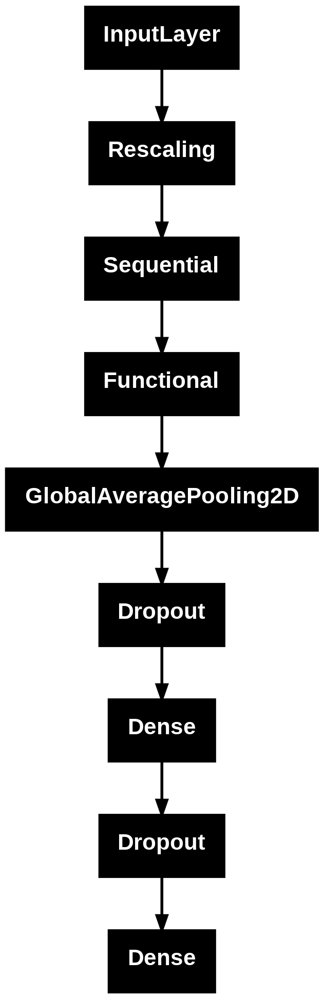

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()
tfk.utils.plot_model(model)

In [ ]:
# Train the model

history = model.fit(
    train_dataset,
    batch_size = BATCH_SIZE,
    epochs = 5,
    validation_data= val_dataset,
    class_weight = class_weights,
    callbacks=tf.keras.callbacks.EarlyStopping(monitor='val_accuracy',
                                                mode='max',
                                                patience=5,
                                                restore_best_weights=True)
).history

Epoch 1/5
337/337 ━━━━━━━━━━━━━━━━━━━━ 479s 1s/step - accuracy: 0.7083 - loss: 0.9595 - val_accuracy: 0.9197 - val_loss: 0.2633
Epoch 2/5
337/337 ━━━━━━━━━━━━━━━━━━━━ 493s 1s/step - accuracy: 0.7520 - loss: 0.7255 - val_accuracy: 0.9247 - val_loss: 0.2529
Epoch 3/5
337/337 ━━━━━━━━━━━━━━━━━━━━ 446s 1s/step - accuracy: 0.7642 - loss: 0.6790 - val_accuracy: 0.9222 - val_loss: 0.2553
Epoch 4/5
337/337 ━━━━━━━━━━━━━━━━━━━━ 498s 1s/step - accuracy: 0.7867 - loss: 0.6098 - val_accuracy: 0.9281 - val_loss: 0.2345
Epoch 5/5
337/337 ━━━━━━━━━━━━━━━━━━━━ 438s 1s/step - accuracy: 0.7959 - loss: 0.5923 - val_accuracy: 0.9348 - val_loss: 0.2167


In [ ]:
# Calculate and print the final validation accuracy
final_val_accuracy = round(max(history['val_accuracy'])* 100, 2)
print(f'Final validation accuracy: {final_val_accuracy}%')

model.save('weights.keras')

Final validation accuracy: 93.48%


#### 📈 Plot the Training History

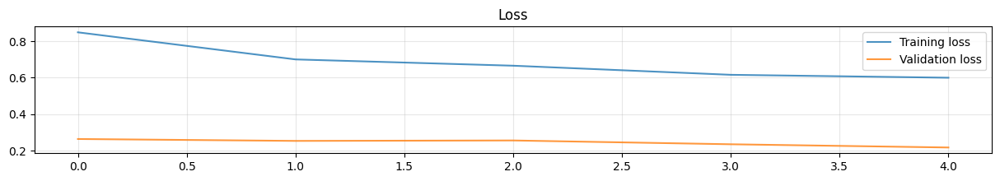

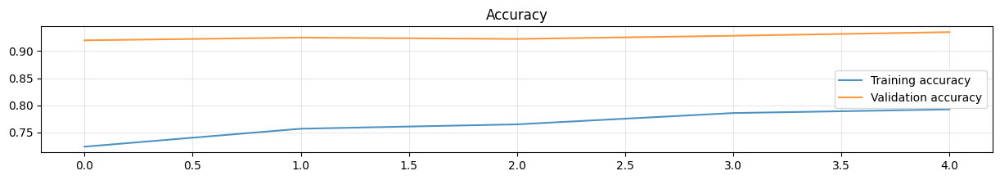

In [ ]:
# Plot training and validation loss
plt.figure(figsize=(15, 2))
plt.plot(history['loss'], label='Training loss', alpha=.8)
plt.plot(history['val_loss'], label='Validation loss', alpha=.8)
plt.title('Loss')
plt.legend()
plt.grid(alpha=.3)

# Plot training and validation accuracy
plt.figure(figsize=(15, 2))
plt.plot(history['accuracy'], label='Training accuracy', alpha=.8)
plt.plot(history['val_accuracy'], label='Validation accuracy', alpha=.8)
plt.title('Accuracy')
plt.legend()
plt.grid(alpha=.3)
plt.show()

##### Plot confusion matrix for the trainning set

Accuracy score over the train set: 0.9299
Precision score over the train set: 0.9317
Recall score over the train set: 0.9299
F1 score over the train set: 0.9299


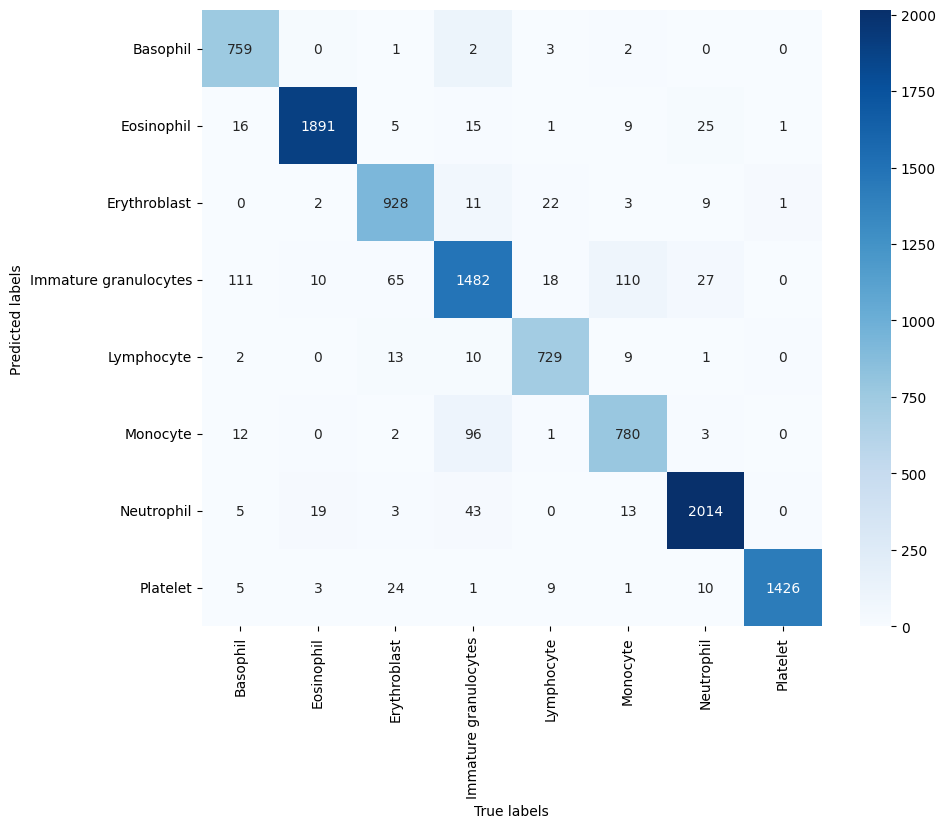

In [ ]:
# Predict the train set
train_predictions = model.predict(X_train, verbose=0)
train_predictions = np.argmax(train_predictions, axis=-1)

# Extract ground truth classes
train_gt = np.argmax(y_train, axis=-1)

train_predictions.shape

#labels
labels = ['Basophil',                    # 0
          'Eosinophil',                  # 1
          'Erythroblast',                # 2
          'Immature granulocytes',       # 3
          'Lymphocyte',                  # 4
          'Monocyte',                    # 5
          'Neutrophil',                  # 6
          'Platelet']                    # 7

# Compute the confusion matrix
cm = confusion_matrix(train_gt, train_predictions)

# Compute the classification metrics
train_accuracy = accuracy_score(train_gt, train_predictions)
train_precision = precision_score(train_gt, train_predictions, average='weighted')
train_recall = recall_score(train_gt, train_predictions, average='weighted')
train_f1 = f1_score(train_gt,train_predictions, average='weighted')
print(f'Accuracy score over the train set: {round(train_accuracy, 4)}')
print(f'Precision score over the train set: {round(train_precision, 4)}')
print(f'Recall score over the train set: {round(train_recall, 4)}')
print(f'F1 score over the train set: {round(train_f1, 4)}')

cm = confusion_matrix(train_gt,train_predictions)

# Create labels combining confusion matrix values
labels_conf = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, annot=labels_conf, fmt='', xticklabels=labels, yticklabels=labels, cmap='Blues')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

##### Plot confusion matrix for the validation set

Accuracy score over the val set: 0.9348
Precision score over the val set: 0.937
Recall score over the val set: 0.9348
F1 score over the val set: 0.9349


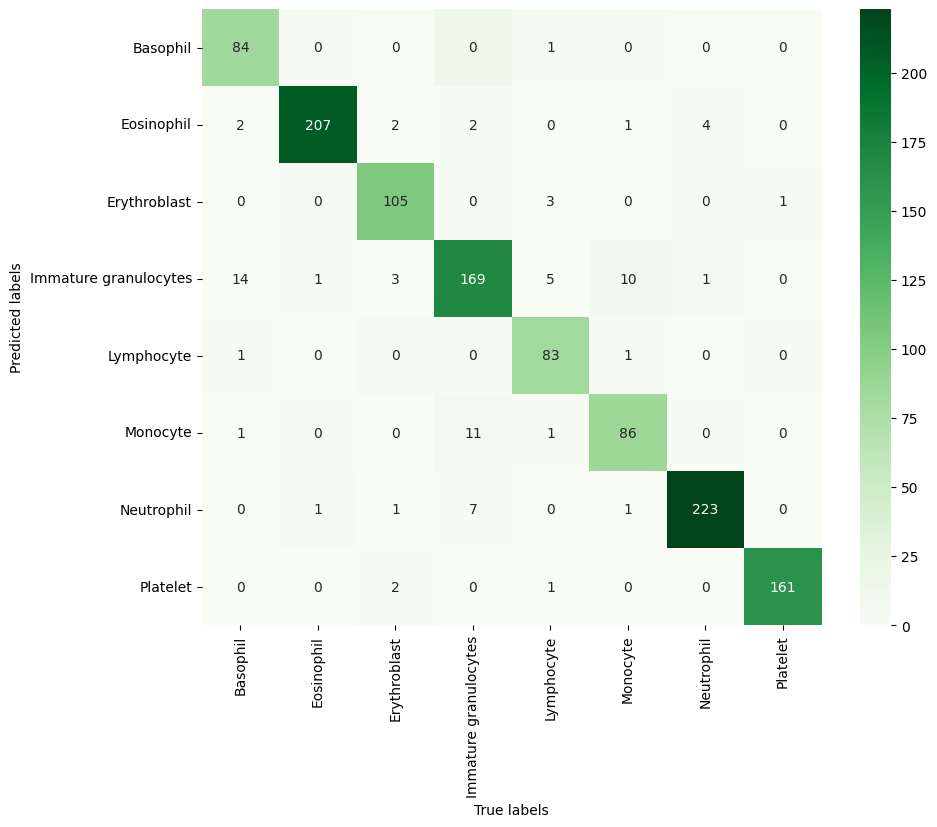

In [ ]:
# Predict the validation set
val_predictions = model.predict(X_val, verbose=0)
val_predictions = np.argmax(val_predictions, axis=-1)

# Extract ground truth classes
val_gt = np.argmax(y_val, axis=-1)

val_predictions.shape

#labels
labels = ['Basophil',                    # 0
          'Eosinophil',                  # 1
          'Erythroblast',                # 2
          'Immature granulocytes',       # 3
          'Lymphocyte',                  # 4
          'Monocyte',                    # 5
          'Neutrophil',                  # 6
          'Platelet']                    # 7

# Compute the confusion matrix
cm = confusion_matrix(val_gt, val_predictions)

# Compute the classification metrics
val_accuracy = accuracy_score(val_gt, val_predictions)
val_precision = precision_score(val_gt, val_predictions, average='weighted')
val_val_recall = recall_score(val_gt, val_predictions, average='weighted')
val_f1 = f1_score(val_gt,val_predictions, average='weighted')
print(f'Accuracy score over the val set: {round(val_accuracy, 4)}')
print(f'Precision score over the val set: {round(val_precision, 4)}')
print(f'Recall score over the val set: {round(val_val_recall, 4)}')
print(f'F1 score over the val set: {round(val_f1, 4)}')

cm = confusion_matrix(val_gt,val_predictions)

# Create labels combining confusion matrix values
labels_conf = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm.T, annot=labels_conf, fmt='', xticklabels=labels, yticklabels=labels, cmap='Greens')
plt.xlabel('True labels')
plt.ylabel('Predicted labels')
plt.show()

# 📊 Prepare Your Submission

To prepare your submission, create a `.zip` file that includes all the necessary code to run your model. It **must** include a `model.py` file with the following class:

```python
# file: model.py
class Model:
    def __init__(self):
        """Initialize the internal state of the model."""

    def predict(self, X):
        """Return a numpy array with the labels corresponding to the input X."""
```

The next cell shows an example implementation of the `model.py` file, which includes loading model weights from the `weights.keras` file and conducting predictions on provided input data. The `.zip` file is created and downloaded in the last notebook cell.

❗ Feel free to modify the method implementations to better fit your specific requirements, but please ensure that the class name and method interfaces remain unchanged.

In [ ]:
%%writefile model.py
import numpy as np

import tensorflow as tf
from tensorflow import keras as tfk
from tensorflow.keras import layers as tfkl


class Model:
    def __init__(self):
        """
        Initialize the internal state of the model. Note that the __init__
        method cannot accept any arguments.

        The following is an example loading the weights of a pre-trained
        model.
        """
        self.neural_network = tfk.models.load_model('VGG16_weights_freez3.keras')

    def predict(self, X):
        """
        Predict the labels corresponding to the input X. Note that X is a numpy
        array of shape (n_samples, 96, 96, 3) and the output should be a numpy
        array of shape (n_samples,). Therefore, outputs must no be one-hot
        encoded.

        The following is an example of a prediction from the pre-trained model
        loaded in the __init__ method.
        """
        X = (X/255).astype(np.float32)
        preds = self.neural_network.predict(X)
        if len(preds.shape) == 2:
            preds = np.argmax(preds, axis=1)
        return preds

Overwriting model.py


In [ ]:
%%writefile model.py
import numpy as np

import tensorflow as tf
from tensorflow import keras as tfk
from tensorflow.keras import layers as tfkl


class Model:
    def __init__(self):
        """
        Initialize the internal state of the model. Note that the __init__
        method cannot accept any arguments.

        The following is an example loading the weights of a pre-trained
        model.
        """
        self.neural_network = tfk.models.load_model('VGG16_weights_freez3.keras')

    def predict(self, X):
        """
        Predict the labels corresponding to the input X. Note that X is a numpy
        array of shape (n_samples, 96, 96, 3) and the output should be a numpy
        array of shape (n_samples,). Therefore, outputs must no be one-hot
        encoded.

        The following is an example of a prediction from the pre-trained model
        loaded in the __init__ method.
        """
        X = (X/255).astype(np.float32)
        preds = self.neural_network.predict(X)
        if len(preds.shape) == 2:
            preds = np.argmax(preds, axis=1)
        return preds

Overwriting model.py


In [ ]:
from datetime import datetime
filename = f'submission_{datetime.now().strftime("%y%m%d_%H%M%S")}.zip'

# Add files to the zip command if needed
!zip {filename} 'model.py' 'VGG16_weights_freez3.keras'

from google.colab import files
files.download(filename)

  adding: model.py (deflated 54%)
  adding: VGG16_weights_freez3.keras (deflated 7%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>